# Singapore HDB Resale: Data Preparation and Exploratory Analysis through 2025

This notebook covers the profiling, cleaning, preparation, and EDA stages of `docs/Assignment Procedure.pdf`. The prediction target is **`resale_price` in SGD**. A basic model comparison remains a separate next step.

Questions: How are area, flat type/model, storey, lease, registration time, and address associated with price? Which unusual observations require cleaning, and which are valid distribution tails?

Source: [HDB / data.gov.sg](https://data.gov.sg/datasets/d_8b84c4ee58e3cfc0ece0d773c8ca6abc/view). We use a locally frozen **2017-01 to 2025-12** subset of the currently available dataset. This is not necessarily the exact historical version published at the end of 2025.

The source uses resale **registration dates**. Floor area may include purchased recess space, upgrading additions, or roof terraces. Transactions such as sales between relatives or partial-share sales are excluded by the provider. Findings describe this transaction sample, rather than all homes or all sales.

**AI declaration:** OpenAI Codex assisted with code, analytical suggestions, and writing. Verification included full notebook execution, inspection of tables and figures, date/encoding checks, and review of cleaning decisions. The group must independently understand and verify all submitted work, explain the decisions, and add member contributions before submission.

## 1. Environment and reproducible snapshots

Run `uv sync --locked`, then `uv run jupyter lab` from the project root. Use the project's Python 3.11 environment.

The notebook reuses the local CSV by default. Set `REFRESH_DATA = True` to replace it with a fresh official download filtered through December 2025, then restore `False`. Metadata records the source, retrieval time, period, and SHA-256; writes replace files rather than append rows. [Official download API documentation](https://guide.data.gov.sg/developer-guide/dataset-apis/download-dataset).

In [1]:
from pathlib import Path
from datetime import datetime
from zoneinfo import ZoneInfo
import hashlib
import io
import json
import time

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd
from IPython.display import display

pd.set_option("display.max_columns", 15)
pd.set_option("display.max_rows", 40)
pd.set_option("display.max_colwidth", 40)
pd.set_option("display.float_format", "{:.3f}".format)
sns.set_theme(style="whitegrid", palette="Set2")
plt.rcParams["figure.dpi"] = 110

DATASET_ID = "d_8b84c4ee58e3cfc0ece0d773c8ca6abc"
SOURCE_URL = f"https://data.gov.sg/datasets/{DATASET_ID}/view"
CUTOFF = "2025-12"
REFRESH_DATA = False
SNAPSHOT = Path("data/raw/hdb_resale_2017_2025.csv")
METADATA = SNAPSHOT.with_suffix(".metadata.json")


In [2]:
if REFRESH_DATA or not SNAPSHOT.exists():
    api = f"https://api-open.data.gov.sg/v1/public/api/datasets/{DATASET_ID}"
    response = requests.get(f"{api}/initiate-download", timeout=60)
    response.raise_for_status()
    download = requests.get(f"{api}/poll-download", timeout=60).json()["data"]
    while not download.get("url"):
        time.sleep(15)
        download = requests.get(f"{api}/poll-download", timeout=60).json()["data"]

    response = requests.get(download["url"], timeout=120)
    response.raise_for_status()
    source = pd.read_csv(io.BytesIO(response.content), dtype="string")
    source_month = pd.to_datetime(source["month"], format="%Y-%m")
    snapshot = source.loc[source_month.between("2017-01-01", "2025-12-31")].copy()
    SNAPSHOT.parent.mkdir(parents=True, exist_ok=True)
    snapshot.to_csv(SNAPSHOT, index=False)
    metadata = {
        "dataset_id": DATASET_ID,
        "source_url": SOURCE_URL,
        "retrieved_at": datetime.now(ZoneInfo("Asia/Shanghai")).isoformat(),
        "cutoff_month": CUTOFF,
        "source_rows": len(source),
        "source_latest_month": source["month"].max(),
        "snapshot_rows": len(snapshot),
        "snapshot_first_month": snapshot["month"].min(),
        "snapshot_last_month": snapshot["month"].max(),
        "snapshot_sha256": hashlib.sha256(SNAPSHOT.read_bytes()).hexdigest(),
    }
    METADATA.write_text(json.dumps(metadata, indent=2) + "\n", encoding="utf-8")

metadata = json.loads(METADATA.read_text(encoding="utf-8"))
assert hashlib.sha256(SNAPSHOT.read_bytes()).hexdigest() == metadata["snapshot_sha256"]
display(pd.Series(metadata, name="Snapshot metadata").to_frame())

,Snapshot metadata
dataset_id,d_8b84c4ee58e3cfc0ece0d773c8ca6abc
source_url,https://data.gov.sg/datasets/d_8b84c...
retrieved_at,2026-10-11T21:23:29.895039+08:00
cutoff_month,2025-12
source_rows,242454
source_latest_month,2026-10
snapshot_rows,222066
snapshot_first_month,2017-01
snapshot_last_month,2025-12
snapshot_sha256,af2ed6574d542771426bf2236c122470d64f...


## 2. Native pandas profiling

Inspect `head()`, `info()`, `dtypes`, and `describe()` before preprocessing. `block` is explicitly read as a string because labels such as `273A` are identifiers. Other fields initially use pandas' native inference. `lease_commence_date` represents a year, even though its inferred dtype is numeric.

In [3]:
raw = pd.read_csv(SNAPSHOT, dtype={"block": "string"})
display(raw.head())
raw.info()
display(raw.dtypes.rename("Inferred dtype").to_frame())
display(raw.describe())
display(raw.describe(include=["object", "string"]))

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
0,2017-01,ANG MO KIO,2 ROOM,406,ANG MO KIO AVE 10,10 TO 12,44.000,Improved,1979,61 years 04 months,232000.000
1,2017-01,ANG MO KIO,3 ROOM,108,ANG MO KIO AVE 4,01 TO 03,67.000,New Generation,1978,60 years 07 months,250000.000
2,2017-01,ANG MO KIO,3 ROOM,602,ANG MO KIO AVE 5,01 TO 03,67.000,New Generation,1980,62 years 05 months,262000.000
3,2017-01,ANG MO KIO,3 ROOM,465,ANG MO KIO AVE 10,04 TO 06,68.000,New Generation,1980,62 years 01 month,265000.000
4,2017-01,ANG MO KIO,3 ROOM,601,ANG MO KIO AVE 5,01 TO 03,67.000,New Generation,1980,62 years 05 months,265000.000


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 222066 entries, 0 to 222065
Data columns (total 11 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   month                222066 non-null  object 
 1   town                 222066 non-null  object 
 2   flat_type            222066 non-null  object 
 3   block                222066 non-null  string 
 4   street_name          222066 non-null  object 
 5   storey_range         222066 non-null  object 
 6   floor_area_sqm       222066 non-null  float64
 7   flat_model           222066 non-null  object 
 8   lease_commence_date  222066 non-null  int64  
 9   remaining_lease      222066 non-null  object 
 10  resale_price         222066 non-null  float64
dtypes: float64(2), int64(1), object(7), string(1)
memory usage: 18.6+ MB


,Inferred dtype
month,object
town,object
flat_type,object
block,string[python]
street_name,object
storey_range,object
floor_area_sqm,float64
flat_model,object
lease_commence_date,int64
remaining_lease,object


,floor_area_sqm,lease_commence_date,resale_price
count,222066.000,222066.000,222066.000
mean,96.770,1996.435,524464.323
std,24.020,14.301,186593.819
min,31.000,1966.000,140000.000
25%,81.000,1985.000,385000.000
50%,93.000,1997.000,492000.000
75%,112.000,2012.000,630000.000
max,366.700,2021.000,1658888.000


,month,town,flat_type,block,street_name,storey_range,flat_model,remaining_lease
count,222066,222066,222066,222066,222066,222066,222066,222066
unique,108,26,7,2745,576,17,21,694
top,2024-07,SENGKANG,4 ROOM,2,YISHUN RING RD,04 TO 06,Model A,94 years 10 months
freq,3036,18155,94091,669,3178,50947,79348,1913


## 3. Literal data quality and duplicate groups

Check missing values, blanks, outer whitespace, label variants, and numeric parsing. Preserve official model labels rather than merge them merely because their spellings differ.

The snapshot contains 308 groups of identical records: 307 pairs and one triplet. The examples below show repeated rows with their group IDs and occurrence counts. Because transaction IDs and unit numbers are unavailable, identical public attributes may describe different sales. Retain these records in the main analysis and compare a deduplicated version later.

In [4]:
literal = pd.read_csv(SNAPSHOT, dtype="string")
quality = pd.DataFrame({
    "missing_count": literal.isna().sum(),
    "blank_count": literal.apply(lambda s: s.str.strip().eq("").sum()),
    "outer_whitespace_count": literal.apply(lambda s: s.ne(s.str.strip()).sum()),
    "unique_count": literal.nunique(),
})
display(quality)

duplicate_counts = raw.groupby(list(raw.columns), dropna=False).size().rename("occurrences")
duplicate_groups = duplicate_counts.loc[duplicate_counts.gt(1)].reset_index()
duplicate_groups.insert(0, "duplicate_group", np.arange(1, len(duplicate_groups) + 1))
with pd.option_context("display.max_columns", None):
    example_rows = raw.reset_index(names="source_row").merge(
        duplicate_groups.head(3), on=list(raw.columns)
    ).sort_values(["duplicate_group", "source_row"])
    display(example_rows[["duplicate_group", "occurrences", "source_row"] + list(raw.columns)])

,missing_count,blank_count,outer_whitespace_count,unique_count
month,0,0,0,108
town,0,0,0,26
flat_type,0,0,0,7
block,0,0,0,2745
street_name,0,0,0,576
storey_range,0,0,0,17
floor_area_sqm,0,0,0,343
flat_model,0,0,0,21
lease_commence_date,0,0,0,56
remaining_lease,0,0,0,694


,duplicate_group,occurrences,source_row,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
0,1,2,224,2017-01,BUKIT MERAH,4 ROOM,106,HENDERSON CRES,07 TO 09,81.000,Improved,1975,57 years,470000.000
1,1,2,243,2017-01,BUKIT MERAH,4 ROOM,106,HENDERSON CRES,07 TO 09,81.000,Improved,1975,57 years,470000.000
2,2,2,304,2017-01,CENTRAL AREA,3 ROOM,271,QUEEN ST,16 TO 18,68.000,Improved,1979,61 years 02 months,470000.000
3,2,2,305,2017-01,CENTRAL AREA,3 ROOM,271,QUEEN ST,16 TO 18,68.000,Improved,1979,61 years 02 months,470000.000
4,3,2,505,2017-01,JURONG EAST,4 ROOM,265,TOH GUAN RD,04 TO 06,101.000,Model A,1998,80 years 09 months,470000.000
5,3,2,510,2017-01,JURONG EAST,4 ROOM,265,TOH GUAN RD,04 TO 06,101.000,Model A,1998,80 years 09 months,470000.000


In [5]:
text_columns = ["town", "flat_type", "block", "street_name", "storey_range", "flat_model"]
variant_tables = []
for column in text_columns:
    labels = literal[column].dropna().drop_duplicates().to_frame("label")
    labels["normalized_label"] = labels["label"].str.strip().str.casefold()
    labels["column"] = column
    variant_tables.append(labels.loc[labels.duplicated("normalized_label", keep=False)])
display(pd.concat(variant_tables, ignore_index=True))

numeric_source_columns = ["floor_area_sqm", "resale_price", "lease_commence_date"]
display(pd.DataFrame({
    "parse_failure_count": {
        c: int((literal[c].notna() & pd.to_numeric(literal[c], errors="coerce").isna()).sum())
        for c in numeric_source_columns
    }
}))

,label,normalized_label,column


,parse_failure_count
floor_area_sqm,0
resale_price,0
lease_commence_date,0


## 4. Type conversion and cleaning

Strip outer whitespace, normalize town/street/flat-type case, and preserve official model labels. Parse numeric fields, dates, lease strings, and storey bounds with pandas.

- `storey_range` describes the floor interval **where the flat is located**, not how many floors it occupies. Sort intervals by their lower bounds and encode them as 0, 1, 2, ... .
- `remaining_lease_years = years + months / 12`.
- `month_index` is elapsed months since January 2017, rather than a recurring 1–12 month label.

Exclude records failing explicit parsing or domain rules, such as nonpositive prices/areas, invalid storey intervals, leases outside 0–99 years, or lease start years after registration. Keep excluded records in `invalid_records` for inspection.

In [6]:
df = raw.copy()
for column in literal.columns.difference(numeric_source_columns):
    df[column] = literal[column].str.strip().replace("", pd.NA)
for column in ["town", "flat_type", "street_name"]:
    df[column] = df[column].str.upper()
for column in numeric_source_columns:
    df[column] = pd.to_numeric(literal[column], errors="coerce")

df["transaction_date"] = pd.to_datetime(df["month"], format="%Y-%m", errors="coerce")
df["transaction_year"] = df["transaction_date"].dt.year
df["month_index"] = (df["transaction_year"] - 2017) * 12 + df["transaction_date"].dt.month - 1

storeys = df["storey_range"].str.extract(r"^(\d{2}) TO (\d{2})$").astype(float)
df["storey_lower"] = storeys[0]
df["storey_upper"] = storeys[1]
storey_order = (
    df[["storey_range", "storey_lower"]].dropna().drop_duplicates()
    .sort_values("storey_lower")["storey_range"].tolist()
)
storey_mapping = {label: rank for rank, label in enumerate(storey_order)}
df["storey_ordinal"] = df["storey_range"].map(storey_mapping)

lease_parts = df["remaining_lease"].str.extract(r"^(\d+) years?(?: (\d+) months?)?$").astype(float)
df["remaining_lease_years"] = lease_parts[0] + lease_parts[1].fillna(0) / 12

In [7]:
issues = pd.DataFrame(index=df.index)
issues["missing_required_field"] = df[raw.columns].isna().any(axis=1)
issues["invalid_month"] = df["transaction_date"].isna() | ~df["month"].str.fullmatch(r"\d{4}-\d{2}", na=False)
issues["outside_snapshot_period"] = ~df["transaction_date"].between("2017-01-01", "2025-12-31")
for column in numeric_source_columns:
    issues[f"invalid_{column}"] = ~np.isfinite(df[column]) | df[column].le(0)
issues["invalid_lease_start_year"] = (
    df["lease_commence_date"].mod(1).ne(0)
    | df["lease_commence_date"].gt(df["transaction_year"])
)
issues["invalid_storey_range"] = (
    df["storey_lower"].isna() | df["storey_lower"].le(0)
    | df["storey_upper"].lt(df["storey_lower"])
)
issues["invalid_remaining_lease"] = (
    df["remaining_lease_years"].isna()
    | ~df["remaining_lease_years"].between(0, 99)
    | lease_parts[1].fillna(0).ge(12)
)
display(issues.sum().rename("Flagged rows").to_frame())

invalid_rows = issues.any(axis=1)
invalid_records = pd.concat([df.loc[invalid_rows], issues.loc[invalid_rows]], axis=1)
display(invalid_records.head(10))
df = df.loc[~invalid_rows].copy()
display(pd.Series({
    "snapshot_rows": len(raw),
    "removed_invalid_rows": int(invalid_rows.sum()),
    "analysis_rows": len(df),
    "duplicates_retained": int(df.duplicated(subset=list(raw.columns)).sum()),
}, name="Cleaning decisions").to_frame())

,Flagged rows
missing_required_field,0
invalid_month,0
outside_snapshot_period,0
invalid_floor_area_sqm,0
invalid_resale_price,0
invalid_lease_commence_date,0
invalid_lease_start_year,0
invalid_storey_range,0
invalid_remaining_lease,0


,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,...,outside_snapshot_period,invalid_floor_area_sqm,invalid_resale_price,invalid_lease_commence_date,invalid_lease_start_year,invalid_storey_range,invalid_remaining_lease


,Cleaning decisions
snapshot_rows,222066
removed_invalid_rows,0
analysis_rows,222066
duplicates_retained,309


### 4.1 Lease consistency exclusion

Compare the recorded lease with the approximation `99 - (registration_year - lease_start_year)`. A very small number of records differ by more than one year. Their causes cannot be established from this dataset, so exclude those flagged records from subsequent analysis and keep the excluded rows in `lease_excluded` for inspection. This is a conservative analysis choice, not a claim that the records are confirmed errors. No lease-residual visualization is needed.

The lease start year is approximately redundant once registration time and remaining lease are available; retain it for EDA but exclude it from candidate model features.

In [8]:
expected_lease = 99 - (df["transaction_year"] - df["lease_commence_date"])
lease_residual = df["remaining_lease_years"] - expected_lease
lease_exclusion = lease_residual.abs().gt(1 + 1e-8)
lease_excluded = df.loc[lease_exclusion].copy()
lease_excluded["lease_residual_years"] = lease_residual.loc[lease_exclusion]
display(pd.Series({
    "lease_inconsistent_rows_excluded": int(lease_exclusion.sum()),
    "excluded_pct": 100 * lease_exclusion.mean(),
    "retained_analysis_rows": int((~lease_exclusion).sum()),
}, name="Lease consistency decision").to_frame())
df = df.loc[~lease_exclusion].copy()

,Lease consistency decision
lease_inconsistent_rows_excluded,128.000
excluded_pct,0.058
retained_analysis_rows,221938.000


## 5. Categorical proportions and one-hot encoding

Use `pd.get_dummies` for `flat_type` and `flat_model`, retaining all categories for EDA. Pie charts show transaction shares. To keep tiny slices readable, categories with individual shares below 1% are grouped into **Other** only in the charts; the tables and encoded columns retain every category. Legends report slice shares, including the combined small categories.

For a future linear model with an intercept, remove one baseline column per categorical field to avoid the full one-hot dependency.

Category distribution: flat_type


,count,share_pct,rare_below_1pct
flat_type,,,
4 ROOM,94030,42.368,False
5 ROOM,54483,24.549,False
3 ROOM,52836,23.807,False
EXECUTIVE,15933,7.179,False
2 ROOM,4492,2.024,False
MULTI-GENERATION,84,0.038,True
1 ROOM,80,0.036,True


Category distribution: flat_model


,count,share_pct,rare_below_1pct
flat_model,,,
Model A,79282,35.723,False
Improved,54249,24.443,False
New Generation,27178,12.246,False
Premium Apartment,24496,11.037,False
Simplified,8508,3.834,False
Apartment,7980,3.596,False
Maisonette,6113,2.754,False
Standard,5957,2.684,False
DBSS,3556,1.602,False


,flat_type_1 ROOM,flat_type_2 ROOM,flat_type_3 ROOM,flat_type_4 ROOM,flat_type_5 ROOM,flat_type_EXECUTIVE,flat_type_MULTI-GENERATION,...,flat_model_Premium Apartment Loft,flat_model_Premium Maisonette,flat_model_Simplified,flat_model_Standard,flat_model_Terrace,flat_model_Type S1,flat_model_Type S2
0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0
1,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0
2,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0
3,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0
4,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0


,One-hot share (%)
flat_type_1 ROOM,0.036
flat_type_2 ROOM,2.024
flat_type_3 ROOM,23.807
flat_type_4 ROOM,42.368
flat_type_5 ROOM,24.549
flat_type_EXECUTIVE,7.179
flat_type_MULTI-GENERATION,0.038
flat_model_2-room,0.163
flat_model_3Gen,0.030
flat_model_Adjoined flat,0.170


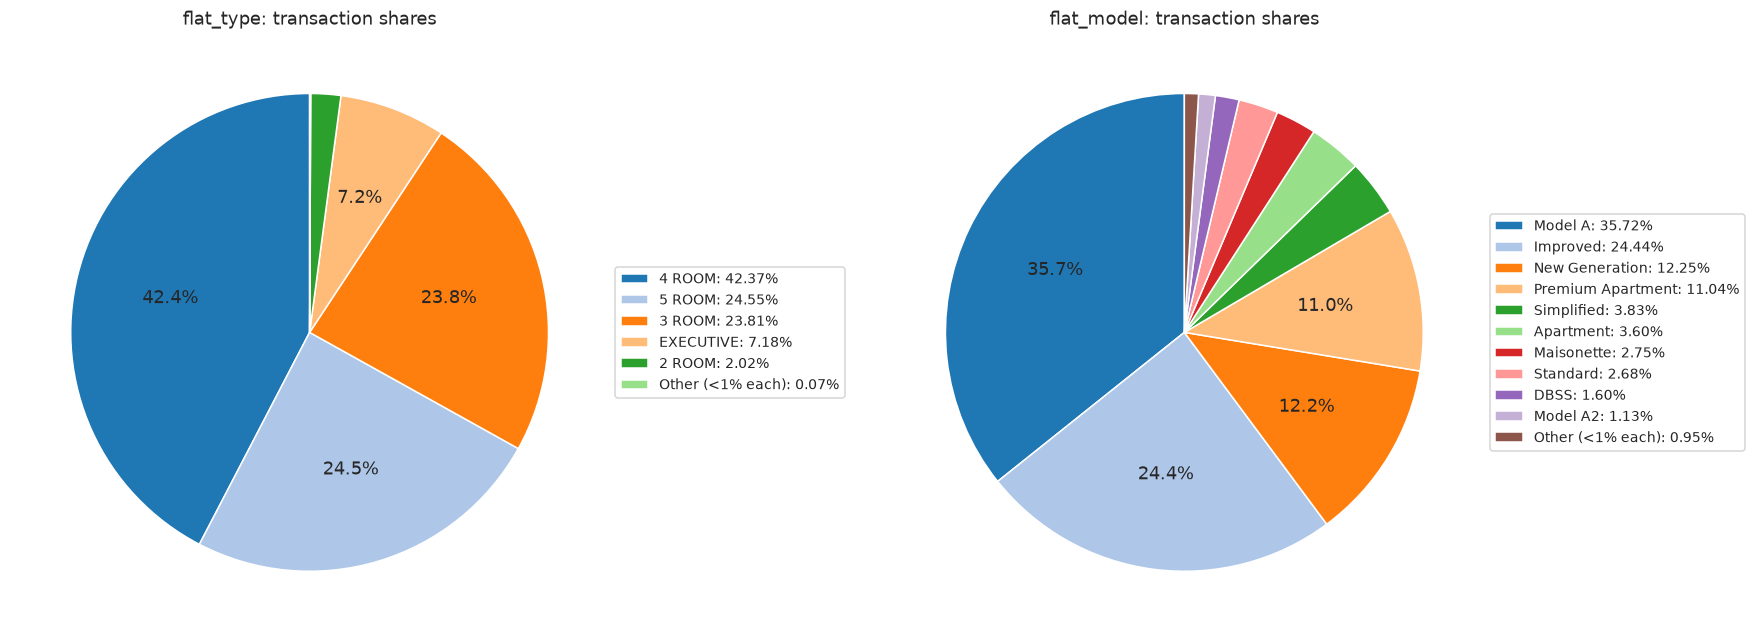

In [9]:
def category_pie(shares, ax, title):
    """Combine small slices for display while preserving the original statistics."""
    visible = shares.loc[shares.ge(1)].copy()
    small = shares.loc[shares.lt(1)].sum()
    if small > 0:
        visible.loc["Other (<1% each)"] = small
    wedges, _, _ = ax.pie(
        visible, startangle=90,
        autopct=lambda pct: f"{pct:.1f}%" if pct >= 5 else "",
        colors=sns.color_palette("tab20", len(visible)),
        wedgeprops={"edgecolor": "white"},
    )
    labels = [f"{label}: {share:.2f}%" for label, share in visible.items()]
    ax.legend(wedges, labels, loc="center left", bbox_to_anchor=(1, .5), fontsize=9)
    ax.set_title(title)


category_columns = ["flat_type", "flat_model"]
category_tables = {}
for column in category_columns:
    counts = df[column].value_counts()
    table = counts.rename("count").to_frame()
    table["share_pct"] = counts / len(df) * 100
    table["rare_below_1pct"] = table["share_pct"].lt(1)
    category_tables[column] = table
    print(f"Category distribution: {column}")
    display(table)

one_hot = pd.get_dummies(df[category_columns], prefix=category_columns, dtype=int)
display(one_hot.head())
display(one_hot.mean().mul(100).rename("One-hot share (%)").to_frame())
for column in category_columns:
    assert one_hot.filter(like=f"{column}_").sum(axis=1).eq(1).all()

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
for column, ax in zip(category_columns, axes):
    category_pie(category_tables[column]["share_pct"], ax, f"{column}: transaction shares")
plt.tight_layout()
plt.show()

## 6. Storey ordinal encoding

The table reports interval bounds, ordinal codes, and proportions; the pie chart follows the same small-slice display rule. Ordinal values express ordering rather than exact floors. Spearman correlation is useful for monotonic associations; Pearson assumes comparable code intervals. Keep the original bounds for auditing, without feeding both bounds and the ordinal into a model.

,ordinal,lower,upper,count,share_pct
storey_range,,,,,
01 TO 03,0,1.000,3.000,39118,17.626
04 TO 06,1,4.000,6.000,50919,22.943
07 TO 09,2,7.000,9.000,46557,20.977
10 TO 12,3,10.000,12.000,41453,18.678
13 TO 15,4,13.000,15.000,21370,9.629
16 TO 18,5,16.000,18.000,10002,4.507
19 TO 21,6,19.000,21.000,4302,1.938
22 TO 24,7,22.000,24.000,3017,1.359
25 TO 27,8,25.000,27.000,1876,0.845


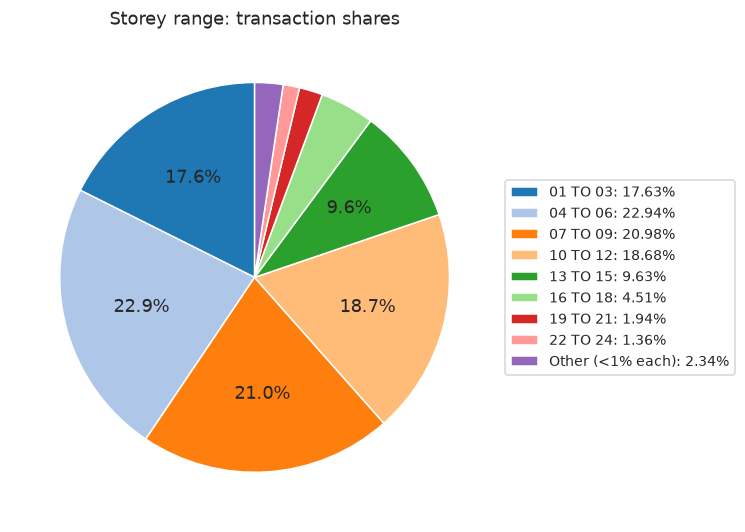

In [10]:
storey_table = df.groupby("storey_range").agg(
    ordinal=("storey_ordinal", "first"),
    lower=("storey_lower", "first"),
    upper=("storey_upper", "first"),
    count=("resale_price", "size"),
).reindex(storey_order)
storey_table["share_pct"] = storey_table["count"] / len(df) * 100
display(storey_table)
fig, ax = plt.subplots(figsize=(9, 5))
category_pie(storey_table["share_pct"], ax, "Storey range: transaction shares")
plt.tight_layout()
plt.show()

## 7. Address hierarchy and map data

`block` is not globally unique. Count the distinct town, street, and block combinations before encoding. A three-field combination identifies a building-level address, not a specific unit.

Use the [official URA Master Plan 2019 planning-area GeoJSON](https://data.gov.sg/datasets/d_4765db0e87b9c86336792efe8a1f7a66/view) for a geographic overview. It is a **planning-area proxy**, not verified HDB town polygons or geocoded transaction locations. Match equal names, associate `KALLANG/WHAMPOA` with the Kallang polygon as an explicit approximation, and dissolve URA Central Area polygons into `CENTRAL AREA`. The [URA data dictionary](https://eservice.ura.gov.sg/reis/dataDictionary) defines Central Area as 11 planning areas. The map is for aggregate illustration only; address target encoding uses the original HDB labels, independently of these geometries.

In [11]:
address_levels = [
    ["town"], ["street_name"], ["block"],
    ["town", "street_name"], ["town", "block"], ["street_name", "block"],
    ["town", "street_name", "block"],
]
address_summary = []
for columns in address_levels:
    sizes = df.groupby(columns).size()
    address_summary.append({
        "level": " + ".join(columns),
        "unique_combinations": len(sizes),
        "min_transactions": sizes.min(),
        "median_transactions": sizes.median(),
        "max_transactions": sizes.max(),
    })
address_summary = pd.DataFrame(address_summary)
display(address_summary)

address_counts = df.groupby(["town", "street_name", "block"]).size().rename("transactions")
display(address_counts.sort_values(ascending=False).head(10).to_frame())
display(pd.Series({
    "street_names_in_multiple_towns": int(df.groupby("street_name")["town"].nunique().gt(1).sum()),
    "block_labels_on_multiple_streets": int(df.groupby("block")["street_name"].nunique().gt(1).sum()),
}, name="Address ambiguity").to_frame())

,level,unique_combinations,min_transactions,median_transactions,max_transactions
0,town,26,542,7577.000,18140
1,street_name,576,1,277.500,3177
2,block,2745,1,51.000,669
3,town + street_name,576,1,277.500,3177
4,town + block,9097,1,21.000,177
5,street_name + block,9670,1,20.000,172
6,town + street_name + block,9670,1,20.000,172


transactions
town        street_name      block              
PUNGGOL     PUNGGOL WALK     308A            172
                             308C            154
QUEENSTOWN  DAWSON RD        87              140
PUNGGOL     PUNGGOL WALK     310B            139
TOA PAYOH   LOR 1A TOA PAYOH 139A            139
QUEENSTOWN  DAWSON RD        88              135
CLEMENTI    CLEMENTI AVE 4   311B            124
QUEENSTOWN  DAWSON RD        86              123
JURONG WEST BOON LAY AVE     187             123
PUNGGOL     PUNGGOL WALK     308B            116

,Address ambiguity
street_names_in_multiple_towns,0
block_labels_on_multiple_streets,1499


In [12]:
BOUNDARY_ID = "d_4765db0e87b9c86336792efe8a1f7a66"
BOUNDARY_URL = f"https://data.gov.sg/datasets/{BOUNDARY_ID}/view"
BOUNDARY_PATH = Path("data/raw/ura_mp2019_planning_areas.geojson")
if not BOUNDARY_PATH.exists():
    url = f"https://api-open.data.gov.sg/v1/public/api/datasets/{BOUNDARY_ID}/poll-download"
    download_url = requests.get(url, timeout=60).json()["data"]["url"]
    response = requests.get(download_url, timeout=120)
    response.raise_for_status()
    BOUNDARY_PATH.write_bytes(response.content)
    boundary_metadata = {
        "dataset_id": BOUNDARY_ID, "source_url": BOUNDARY_URL,
        "retrieved_at": datetime.now(ZoneInfo("Asia/Shanghai")).isoformat(),
        "sha256": hashlib.sha256(response.content).hexdigest(),
    }
    BOUNDARY_PATH.with_suffix(".metadata.json").write_text(
        json.dumps(boundary_metadata, indent=2) + "\n", encoding="utf-8"
    )

areas = gpd.read_file(BOUNDARY_PATH).to_crs(epsg=3414)
areas["map_town"] = areas["PLN_AREA_N"].replace({"KALLANG": "KALLANG/WHAMPOA"})
areas.loc[areas["CA_IND"].eq("Y"), "map_town"] = "CENTRAL AREA"
town_boundaries = areas[["map_town", "geometry"]].dissolve(by="map_town").reset_index()
town_statistics = df.groupby("town").agg(
    transactions=("resale_price", "size"), median_price=("resale_price", "median")
)
town_statistics["share_pct"] = town_statistics["transactions"] / len(df) * 100
town_map = town_boundaries.merge(town_statistics, left_on="map_town", right_index=True, how="left")
display(pd.Series({
    "HDB_town_labels": df["town"].nunique(),
    "matched_town_labels": df["town"].isin(town_boundaries["map_town"]).groupby(df["town"]).all().sum(),
    "Central_Area_planning_polygons": areas["CA_IND"].eq("Y").sum(),
}, name="Map matching audit").to_frame())
display(town_statistics.sort_values("transactions", ascending=False).head())

,Map matching audit
HDB_town_labels,26
matched_town_labels,26
Central_Area_planning_polygons,11


,transactions,median_price,share_pct
town,,,
SENGKANG,18140,515000.000,8.173
PUNGGOL,16146,525944.000,7.275
WOODLANDS,15743,455000.000,7.093
TAMPINES,15144,538888.000,6.824
YISHUN,15129,428000.000,6.817


## 8. Hierarchically smoothed address target encoding

Encode the hierarchy **global → Town → Town + Street → Town + Street + Block**. Each level shrinks its observed target mean towards the already smoothed parent:

\[
TE_g = \frac{n_g\bar y_g + \alpha_g TE_{parent(g)}}{n_g+\alpha_g}.
\]

The illustrative pseudo-counts are 50 for towns, 20 for streets, and 10 for buildings; they are fixed demonstration settings, not tuned optima. Sparse buildings rely more on their street prior. An unseen building falls back to its street, an unseen street to its town, and an unseen town to the reference global mean. The final `address_te` is the building-level result; parent encodings are shown for interpretation, not duplicated as model inputs.

**Prevent target leakage:** encode each year using only earlier years. Use 2017 as historical warm-up; 2018–2024 receive forward, year-block out-of-fold encodings; 2025 is the test period, encoded using 2017–2024 only. There is no eligible history for 2017, so retain it in EDA but exclude it from encoded feature comparisons. A row's own price and later prices never enter its encoding. For future model evaluation, fit and tune all other transformations inside the same chronological scheme.

In [13]:
address_columns = ["town", "street_name", "block"]


def hierarchical_target_encode(reference, addresses):
    """Fit hierarchical means on reference prices and transform address-only rows."""
    global_mean = reference["resale_price"].mean()
    result = pd.DataFrame(index=addresses.index)
    parent = None
    for level, (strength, name) in enumerate(zip([50, 20, 10], ["town_te", "street_te", "address_te"]), 1):
        keys = address_columns[:level]
        stats = reference.groupby(keys)["resale_price"].agg(["sum", "count"]).reset_index()
        if level == 1:
            stats["prior"] = global_mean
            fallback = global_mean
        else:
            stats = stats.merge(parent.rename(columns={"encoding": "prior"}), on=keys[:-1])
            fallback = result.iloc[:, -1]
        stats["encoding"] = (stats["sum"] + strength * stats["prior"]) / (stats["count"] + strength)
        parent = stats[keys + ["encoding"]]
        mapped = addresses[keys].merge(parent, on=keys, how="left", sort=False)["encoding"]
        result[name] = pd.Series(mapped.to_numpy(), index=addresses.index).fillna(fallback)
    return result


encoding_folds = []
for year in sorted(df["transaction_year"].unique()):
    if year == 2017:
        continue
    reference = df.loc[df["transaction_year"].lt(year)]
    current = df.loc[df["transaction_year"].eq(year)]
    fold = hierarchical_target_encode(reference, current[address_columns])
    fold["encoding_year"] = int(year)
    fold["reference_last_year"] = int(reference["transaction_year"].max())
    fold["split"] = "test" if year == 2025 else "train"
    encoding_folds.append(fold)

address_encoding = pd.concat(encoding_folds).sort_index()
df["address_te"] = address_encoding["address_te"]
assert address_encoding["reference_last_year"].lt(address_encoding["encoding_year"]).all()
assert address_encoding[["town_te", "street_te", "address_te"]].notna().all().all()
display(address_encoding.groupby(["encoding_year", "reference_last_year", "split"]).size().rename("rows").to_frame())
display(df.loc[address_encoding.index, ["month"] + address_columns].join(
    address_encoding[["town_te", "street_te", "address_te"]]
).head(8))

,,,rows
encoding_year,reference_last_year,split,
2018,2017,train,21557
2019,2018,train,22185
2020,2019,train,23333
2021,2020,train,29081
2022,2021,train,26715
2023,2022,train,25724
2024,2023,train,27812
2025,2024,test,25022


,month,town,street_name,block,town_te,street_te,address_te
20509,2018-01,ANG MO KIO,ANG MO KIO AVE 3,314,423571.876,382984.290,322873.112
20510,2018-01,ANG MO KIO,ANG MO KIO AVE 4,109,423571.876,380927.815,357251.656
20511,2018-01,ANG MO KIO,ANG MO KIO AVE 5,150,423571.876,385548.295,405421.765
20512,2018-01,ANG MO KIO,ANG MO KIO AVE 10,559,423571.876,360718.873,344145.915
20513,2018-01,ANG MO KIO,ANG MO KIO AVE 10,461,423571.876,360718.873,349156.338
20514,2018-01,ANG MO KIO,ANG MO KIO AVE 10,466,423571.876,360718.873,339227.766
20515,2018-01,ANG MO KIO,ANG MO KIO AVE 5,152,423571.876,385548.295,385548.295
20516,2018-01,ANG MO KIO,ANG MO KIO AVE 3,348,423571.876,382984.290,389820.241


## 9. Numeric distributions and statistical outliers

Summarize area, price, remaining lease, storey ordinal, elapsed month, and lease start year. Show each field in one **histogram + KDE + quantile-lines** panel: Q1, median, and Q3 mark the central distribution. Storey ordinal uses a wider KDE bandwidth (`bw_adjust=4`) to summarize the distribution envelope rather than produce a separate smoothing peak at each integer code. The histogram retains the discrete intervals. KDE remains a descriptive smoother and does not recover exact floors or turn ordinal values into continuous measurements.

IQR fences flag distribution tails rather than confirmed errors. Retain those observations, inspect the largest values, and compare global area thresholds with within-flat-type thresholds. Any later trimming decision needs training-only thresholds and a basic model comparison.

In [14]:
numeric_columns = [
    "floor_area_sqm", "resale_price", "remaining_lease_years",
    "storey_ordinal", "month_index", "lease_commence_date",
]
numeric_summary = df[numeric_columns].describe(percentiles=[.01, .25, .5, .75, .99]).T
numeric_summary["skewness"] = df[numeric_columns].skew()
display(numeric_summary)

q1 = df[numeric_columns].quantile(.25)
q3 = df[numeric_columns].quantile(.75)
iqr = q3 - q1
lower_fence = q1 - 1.5 * iqr
upper_fence = q3 + 1.5 * iqr
outlier_flags = df[numeric_columns].lt(lower_fence) | df[numeric_columns].gt(upper_fence)
outlier_summary = pd.DataFrame({
    "lower_fence": lower_fence, "upper_fence": upper_fence,
    "lower_tail_count": df[numeric_columns].lt(lower_fence).sum(),
    "upper_tail_count": df[numeric_columns].gt(upper_fence).sum(),
    "outlier_count": outlier_flags.sum(),
    "outlier_pct": outlier_flags.mean() * 100,
})
display(outlier_summary)

,count,mean,std,min,1%,25%,50%,75%,99%,max,skewness
floor_area_sqm,221938.000,96.773,24.022,31.000,47.000,81.000,93.000,112.000,151.000,366.700,0.257
resale_price,221938.000,524419.745,186582.362,140000.000,230000.000,385000.000,492000.000,630000.000,1070000.000,1658888.000,0.960
remaining_lease_years,221938.000,74.249,14.232,40.083,46.250,62.500,74.083,88.667,95.250,97.750,-0.020
storey_ordinal,221938.000,2.256,1.980,0.000,0.000,1.000,2.000,3.000,9.000,16.000,1.606
month_index,221938.000,56.178,30.181,0.000,1.000,31.000,57.000,82.000,106.000,107.000,-0.120
lease_commence_date,221938.000,1996.431,14.301,1966.000,1969.000,1985.000,1997.000,2012.000,2020.000,2021.000,0.064


,lower_fence,upper_fence,lower_tail_count,upper_tail_count,outlier_count,outlier_pct
floor_area_sqm,34.500,158.500,102,1085,1187,0.535
resale_price,17500.000,997500.000,0,4054,4054,1.827
remaining_lease_years,23.250,127.917,0,0,0,0.000
storey_ordinal,-2.000,6.000,0,8217,8217,3.702
month_index,-45.500,158.500,0,0,0,0.000
lease_commence_date,1944.500,2052.500,0,0,0,0.000


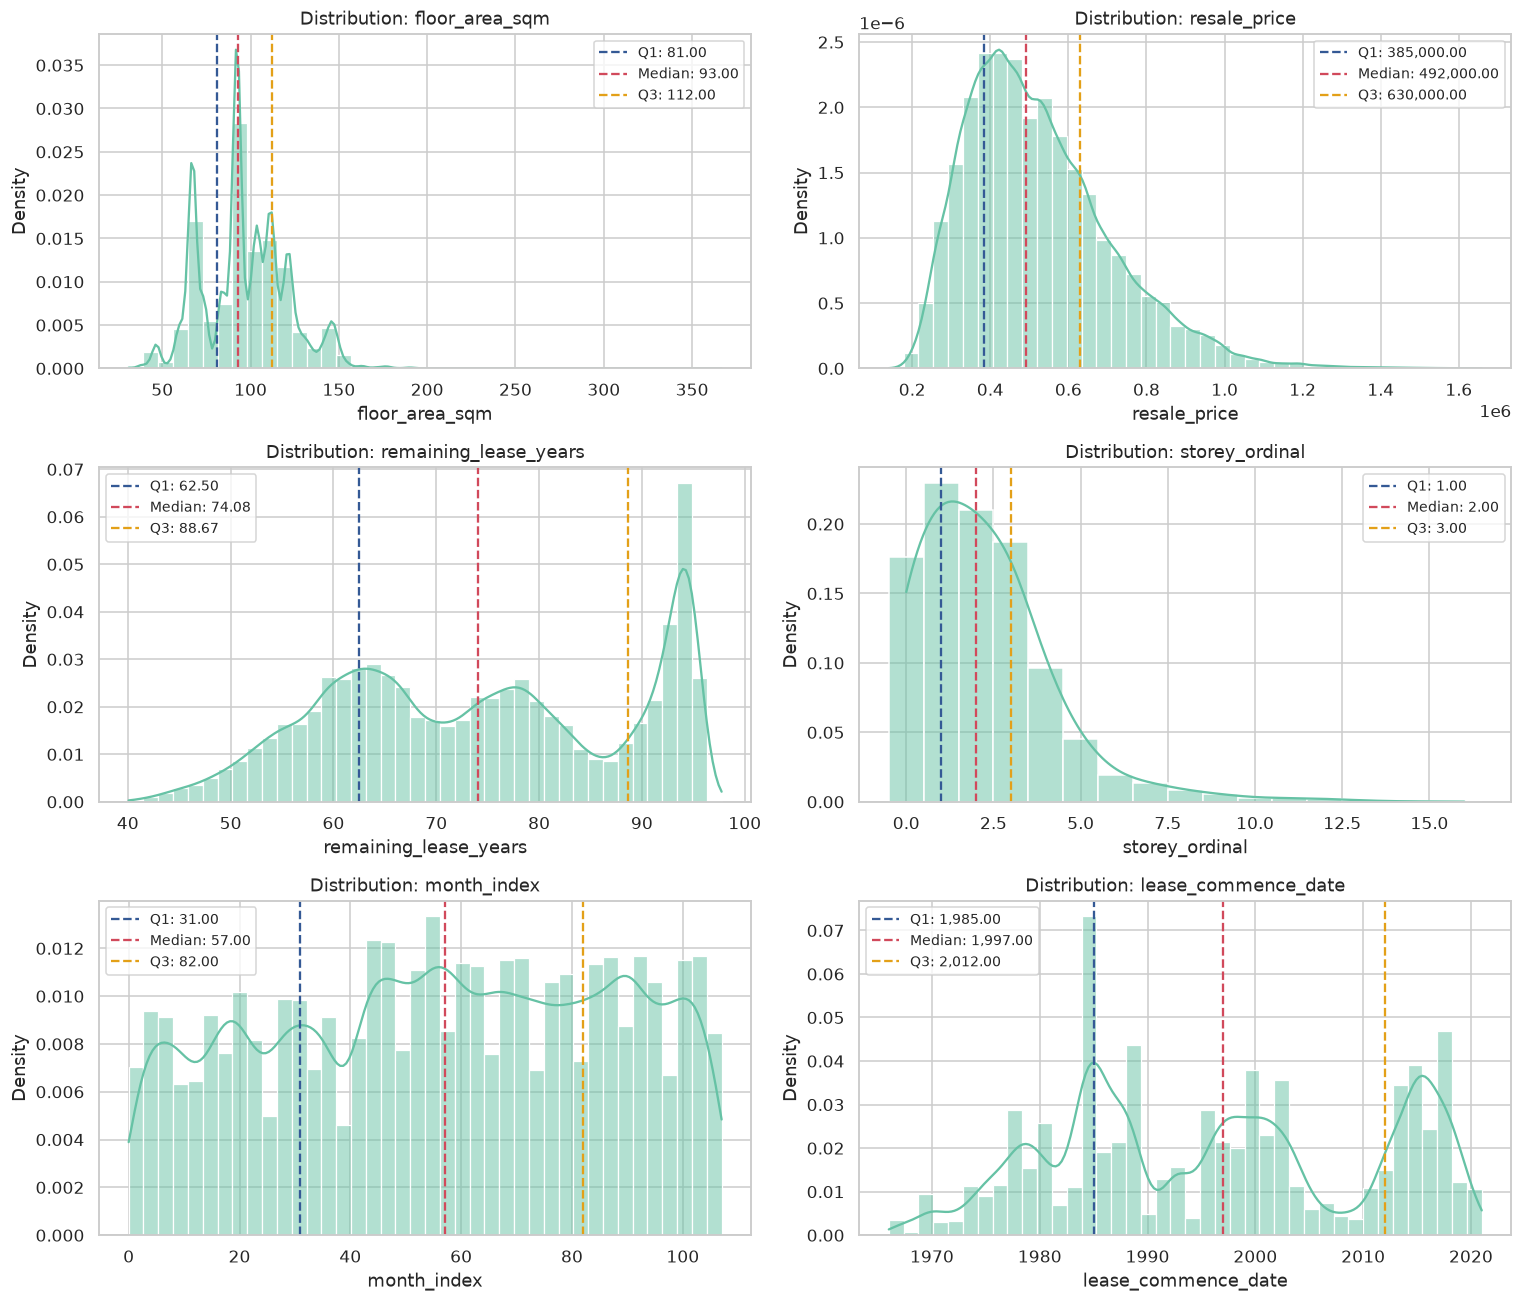

,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
182823,2024-07,KALLANG/WHAMPOA,3 ROOM,53,JLN MA'MOR,01 TO 03,366.700,Terrace,1972,47 years,1568000.000
19693,2017-12,KALLANG/WHAMPOA,3 ROOM,65,JLN MA'MOR,01 TO 03,249.000,Terrace,1972,53 years 07 months,1053888.000
92512,2021-03,BISHAN,EXECUTIVE,446,BRIGHT HILL DR,07 TO 09,243.000,Maisonette,1990,68 years 01 month,1092888.000
94959,2021-04,BISHAN,EXECUTIVE,454,SIN MING AVE,10 TO 12,243.000,Maisonette,1989,67 years 08 months,1001000.000
107851,2021-09,KALLANG/WHAMPOA,3 ROOM,46,JLN BAHAGIA,01 TO 03,241.000,Terrace,1972,49 years 10 months,1235000.000
35797,2018-09,KALLANG/WHAMPOA,3 ROOM,41,JLN BAHAGIA,01 TO 03,237.000,Terrace,1972,52 years 10 months,1185000.000
95808,2021-04,KALLANG/WHAMPOA,3 ROOM,61,JLN TENTERAM,01 TO 03,222.000,Terrace,1972,50 years 03 months,1100000.000
8868,2017-06,KALLANG/WHAMPOA,3 ROOM,38,JLN BAHAGIA,01 TO 03,215.000,Terrace,1972,54 years 01 month,830000.000


,month,town,flat_type,block,street_name,storey_range,floor_area_sqm,flat_model,lease_commence_date,remaining_lease,resale_price
212073,2025-06,QUEENSTOWN,5 ROOM,92,DAWSON RD,22 TO 24,122.000,Premium Apartment Loft,2016,89 years 11 months,1658888.000
199476,2025-11,BISHAN,5 ROOM,275A,BISHAN ST 24,34 TO 36,120.000,DBSS,2011,84 years 10 months,1632000.000
199498,2025-11,BISHAN,EXECUTIVE,135,BISHAN ST 12,22 TO 24,163.000,Maisonette,1987,60 years 08 months,1600000.000
202785,2025-08,CENTRAL AREA,5 ROOM,1G,CANTONMENT RD,49 TO 51,105.000,Type S2,2011,84 years 05 months,1600000.000
218475,2025-01,TOA PAYOH,5 ROOM,138A,LOR 1A TOA PAYOH,19 TO 21,117.000,DBSS,2012,86 years 06 months,1600000.000
202786,2025-09,CENTRAL AREA,5 ROOM,1A,CANTONMENT RD,40 TO 42,107.000,Type S2,2011,84 years 04 months,1590000.000
174171,2024-06,BUKIT MERAH,5 ROOM,9B,BOON TIONG RD,34 TO 36,112.000,Improved,2016,90 years 08 months,1588000.000
174172,2024-06,BUKIT MERAH,5 ROOM,96A,HENDERSON RD,46 TO 48,113.000,Improved,2019,94 years,1588000.000


In [15]:
fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for column, ax in zip(numeric_columns, axes.flat):
    is_storey = column == "storey_ordinal"
    sns.histplot(data=df, x=column, bins=40, discrete=is_storey, stat="density", kde=True,
                 kde_kws={"cut": 0, "bw_adjust": 4 if is_storey else 1}, ax=ax)
    for quantile, label, color in [(0.25, "Q1", "#345995"), (0.5, "Median", "#d1495b"), (0.75, "Q3", "#e3a018")]:
        value = df[column].quantile(quantile)
        ax.axvline(value, linestyle="--", color=color, label=f"{label}: {value:,.2f}")
    ax.set_title(f"Distribution: {column}")
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

display(df.nlargest(8, "floor_area_sqm")[list(raw.columns)])
display(df.nlargest(8, "resale_price")[list(raw.columns)])

In [16]:
type_outliers = df.groupby("flat_type")["floor_area_sqm"].agg(
    q1=lambda s: s.quantile(.25), q3=lambda s: s.quantile(.75), count="size"
)
type_outliers["lower_fence"] = type_outliers["q1"] - 1.5 * (type_outliers["q3"] - type_outliers["q1"])
type_outliers["upper_fence"] = type_outliers["q3"] + 1.5 * (type_outliers["q3"] - type_outliers["q1"])
within_type_area_outlier = (
    df["floor_area_sqm"].lt(df["flat_type"].map(type_outliers["lower_fence"]))
    | df["floor_area_sqm"].gt(df["flat_type"].map(type_outliers["upper_fence"]))
)
type_outliers["within_type_outlier_count"] = within_type_area_outlier.groupby(df["flat_type"]).sum()
display(type_outliers)

,q1,q3,count,lower_fence,upper_fence,within_type_outlier_count
flat_type,,,,,,
1 ROOM,31.000,31.000,80,31.000,31.000,0
2 ROOM,45.000,47.000,4492,42.000,50.000,630
3 ROOM,65.000,70.000,52836,57.500,77.500,4030
4 ROOM,91.000,101.000,94030,76.000,116.000,304
5 ROOM,112.000,122.000,54483,97.000,137.000,752
EXECUTIVE,141.000,148.000,15933,130.500,158.500,2957
MULTI-GENERATION,159.000,166.750,84,147.375,178.375,22


## 10. Registration time and coverage

Check all expected months and summarize monthly transactions, price, area, and lease. Time is a continuous coordinate, not a set of independent random observations. Price-related plots are collected after the correlation tables in Section 12.

In [17]:
monthly = df.groupby("transaction_date").agg(
    transactions=("resale_price", "size"),
    median_price=("resale_price", "median"),
    median_area=("floor_area_sqm", "median"),
    median_remaining_lease=("remaining_lease_years", "median"),
)
expected_months = pd.date_range("2017-01-01", "2025-12-01", freq="MS")
display(pd.Series({
    "observed_months": len(monthly),
    "expected_months": len(expected_months),
    "missing_months": len(expected_months.difference(monthly.index)),
    "month_index_min": df["month_index"].min(),
    "month_index_max": df["month_index"].max(),
}, name="Time coverage").to_frame())
display(monthly.head())
display(monthly.tail())

,Time coverage
observed_months,108
expected_months,108
missing_months,0
month_index_min,0
month_index_max,107


,transactions,median_price,median_area,median_remaining_lease
transaction_date,,,,
2017-01-01,1185,405000.000,95.000,71.667
2017-02-01,1085,415000.000,96.000,74.500
2017-03-01,1903,415000.000,95.000,74.583
2017-04-01,1839,408000.000,95.000,74.000
2017-05-01,1980,410000.000,96.000,74.583


,transactions,median_price,median_area,median_remaining_lease
transaction_date,,,,
2025-08-01,2202,622000.000,93.000,71.667
2025-09-01,2174,645000.000,93.000,72.250
2025-10-01,1338,620000.000,93.000,70.625
2025-11-01,1658,618000.000,93.000,71.083
2025-12-01,2024,635000.000,93.000,71.083


## 11. Price correlations and grouped checks

Pearson measures linear association; Spearman measures monotonic rank association. A one-hot Pearson correlation is a point-biserial association for membership in a category. Neither coefficient establishes causation or model importance. Do not include storey bounds or registration year again when their encoded representations already express them.

First report non-address correlations over all retained EDA rows. Then compare all features, including `address_te`, on the same **2018–2025** subset with historical encodings. A target-derived feature's correlation is not independent proof of location's causal effect or a substitute for held-out model evaluation.

In [18]:
continuous_features = [
    "floor_area_sqm", "remaining_lease_years", "storey_ordinal",
    "month_index", "lease_commence_date",
]
encoded = pd.concat([df[continuous_features], one_hot], axis=1)
price_correlations = pd.DataFrame({
    "pearson": encoded.corrwith(df["resale_price"], method="pearson"),
    "spearman": encoded.corrwith(df["resale_price"], method="spearman"),
})
price_correlations["kind"] = ["continuous_or_ordinal" if c in continuous_features else "one_hot" for c in encoded.columns]
price_correlations = price_correlations.loc[
    price_correlations["pearson"].abs().sort_values(ascending=False).index
]
display(price_correlations)

,pearson,spearman,kind
floor_area_sqm,0.572,0.610,continuous_or_ordinal
flat_type_3 ROOM,-0.458,-0.521,one_hot
month_index,0.396,0.420,continuous_or_ordinal
lease_commence_date,0.371,0.412,continuous_or_ordinal
storey_ordinal,0.342,0.247,continuous_or_ordinal
flat_type_EXECUTIVE,0.308,0.298,one_hot
remaining_lease_years,0.304,0.328,continuous_or_ordinal
flat_type_5 ROOM,0.304,0.335,one_hot
flat_model_New Generation,-0.281,-0.313,one_hot
flat_model_Maisonette,0.231,0.206,one_hot


In [19]:
history_index = address_encoding.index
history_features = encoded.loc[history_index].join(df.loc[history_index, ["address_te"]])
history_correlations = pd.DataFrame({
    "pearson": history_features.corrwith(df.loc[history_index, "resale_price"], method="pearson"),
    "spearman": history_features.corrwith(df.loc[history_index, "resale_price"], method="spearman"),
}).sort_values("pearson", ascending=False)
display(history_correlations)

,pearson,spearman
address_te,0.807,0.788
floor_area_sqm,0.577,0.613
month_index,0.397,0.418
lease_commence_date,0.365,0.408
storey_ordinal,0.341,0.247
flat_type_EXECUTIVE,0.309,0.299
remaining_lease_years,0.306,0.328
flat_type_5 ROOM,0.304,0.336
flat_model_Maisonette,0.231,0.206
flat_model_Apartment,0.196,0.198


### 11.1 Overall versus within-group associations

Compare area/lease correlations within flat types and registration years, then inspect the 4 ROOM model mix. Overall associations can differ from within-group associations because area, flat type, building generation, time, and location are entangled. Do not label this Simpson's paradox without investigating the direction changes and their causes.

1 ROOM has constant floor area in this sample. Its undefined area correlation appears as NaN; this does not indicate missing source measurements.

In [20]:
group_correlations = []
for grouping in ["flat_type", "transaction_year"]:
    for group, part in df.groupby(grouping):
        correlations = part[["floor_area_sqm", "remaining_lease_years", "resale_price"]].corr()["resale_price"]
        group_correlations.append({
            "grouping": grouping, "group": str(group), "count": len(part),
            "area_price_pearson": correlations["floor_area_sqm"],
            "lease_price_pearson": correlations["remaining_lease_years"],
        })
group_correlations = pd.DataFrame(group_correlations)
display(group_correlations)

four_room_models = df.loc[df["flat_type"].eq("4 ROOM")].groupby("flat_model").agg(
    count=("resale_price", "size"),
    median_area=("floor_area_sqm", "median"),
    median_lease=("remaining_lease_years", "median"),
    median_price=("resale_price", "median"),
).sort_values("count", ascending=False)
display(four_room_models)

,grouping,group,count,area_price_pearson,lease_price_pearson
0,flat_type,1 ROOM,80,NaN,-0.799
1,flat_type,2 ROOM,4492,0.138,0.445
2,flat_type,3 ROOM,52836,0.237,0.435
3,flat_type,4 ROOM,94030,-0.061,0.321
4,flat_type,5 ROOM,54483,0.014,0.086
5,flat_type,EXECUTIVE,15933,0.346,-0.520
6,flat_type,MULTI-GENERATION,84,0.305,-0.638
7,transaction_year,2017,20509,0.634,0.351
8,transaction_year,2018,21557,0.631,0.321
9,transaction_year,2019,22185,0.635,0.315


,count,median_area,median_lease,median_price
flat_model,,,,
Model A,58077,94.000,80.750,520000.000
Premium Apartment,12846,93.000,89.417,526000.000
New Generation,9916,92.000,59.500,448000.000
Simplified,6235,84.000,64.667,420000.000
Model A2,2511,90.000,77.667,416000.000
Improved,2405,84.000,53.250,460000.000
DBSS,1467,91.000,91.667,738000.000
Type S1,360,94.000,88.500,1009000.000
Premium Apartment Loft,95,97.000,93.917,938000.000


### 11.2 Duplicate and price-tail sensitivity

After the lease exclusion, compare the main analysis with deduplication and with restricting prices to the global IQR range. The latter deliberately truncates the target distribution and changes the study population; it is a descriptive comparison, not the default cleaning policy or evidence of better model performance.

In [21]:
variants = {
    "all_valid_rows": pd.Series(True, index=df.index),
    "deduplicated": ~df.duplicated(subset=list(raw.columns)),
    "price_inside_global_IQR": ~outlier_flags["resale_price"],
}
sensitivity = []
for name, mask in variants.items():
    part = df.loc[mask]
    for feature in continuous_features:
        sensitivity.append({
            "variant": name, "rows": len(part), "feature": feature,
            "pearson": part[feature].corr(part["resale_price"]),
            "spearman": part[feature].corr(part["resale_price"], method="spearman"),
        })
sensitivity = pd.DataFrame(sensitivity)
display(sensitivity.pivot(index="feature", columns="variant", values="pearson"))
display(sensitivity.groupby("variant")["rows"].first().to_frame())

variant,all_valid_rows,deduplicated,price_inside_global_IQR
feature,,,
floor_area_sqm,0.572,0.573,0.591
lease_commence_date,0.371,0.371,0.375
month_index,0.396,0.396,0.383
remaining_lease_years,0.304,0.304,0.311
storey_ordinal,0.342,0.342,0.287


,rows
variant,
all_valid_rows,221938
deduplicated,221629
price_inside_global_IQR,217884


## 12. Price relationship visualizations

All relationship plots are collected here after the correlation analysis: the numeric heatmap, one-hot associations, sampled scatterplots, category price distributions, storey-price profile, monthly/yearly price trends, and maps.

Category boxplots hide plotted outlier points only for readability; rows remain in the data. Scatterplots use a reproducible sample, while tables, boxplots, trends, and maps use all eligible records. Sample counts should guide interpretation of rare categories and high storeys.

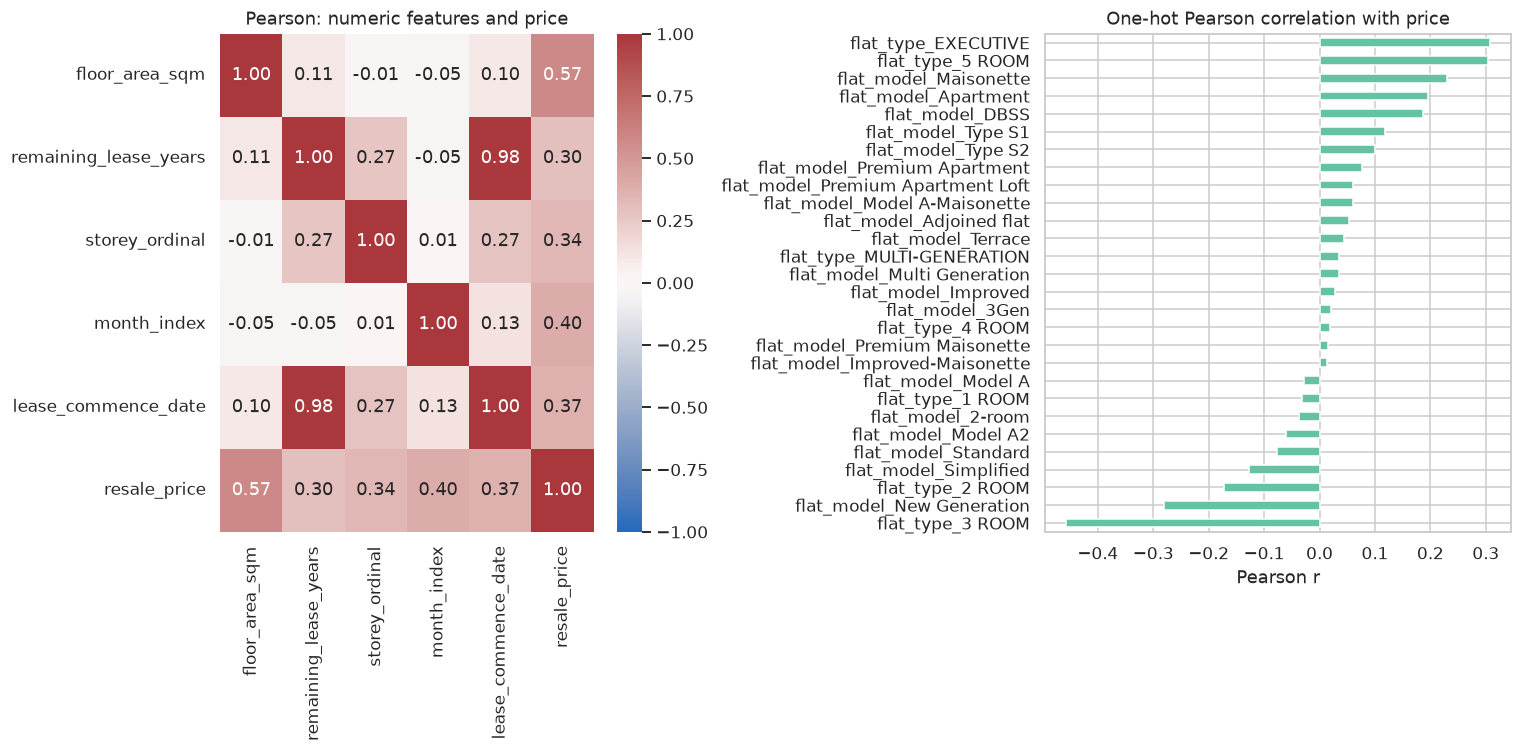

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
numeric_corr = df[continuous_features + ["resale_price"]].corr()
sns.heatmap(numeric_corr, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Pearson: numeric features and price")
price_correlations.loc[one_hot.columns, "pearson"].sort_values().plot.barh(ax=axes[1])
axes[1].set(title="One-hot Pearson correlation with price", xlabel="Pearson r", ylabel="")
plt.tight_layout()
plt.show()

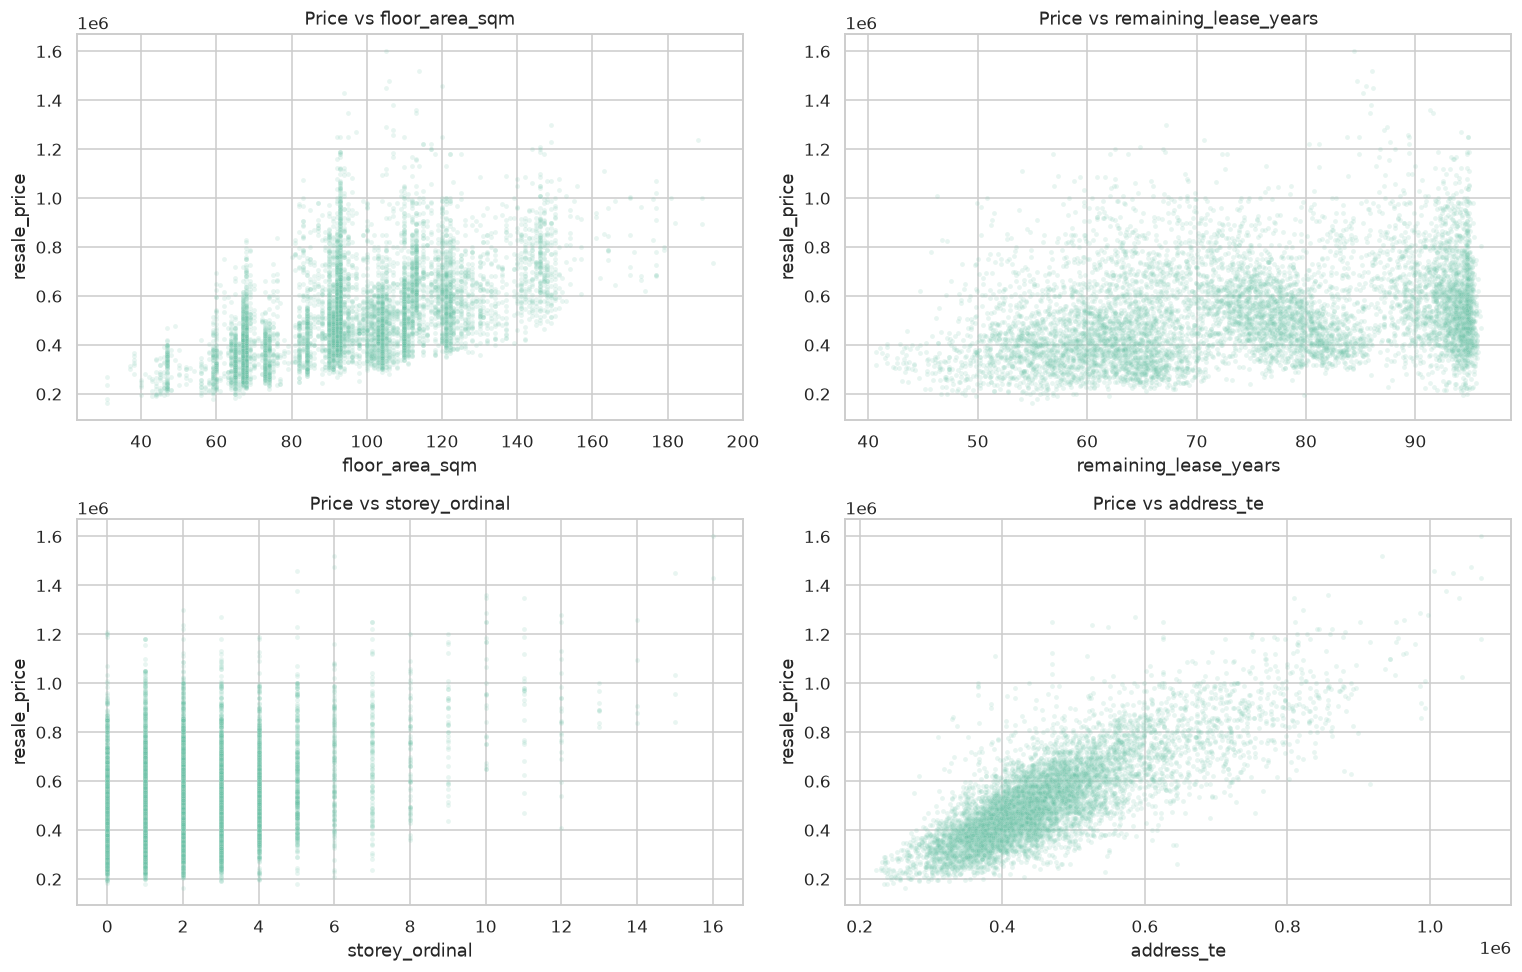

In [23]:
sample = df.sample(n=min(8000, len(df)), random_state=42)
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for column, ax in zip(["floor_area_sqm", "remaining_lease_years", "storey_ordinal", "address_te"], axes.flat):
    sns.scatterplot(data=sample, x=column, y="resale_price", alpha=.15, s=10, ax=ax)
    ax.set_title(f"Price vs {column}")
plt.tight_layout()
plt.show()

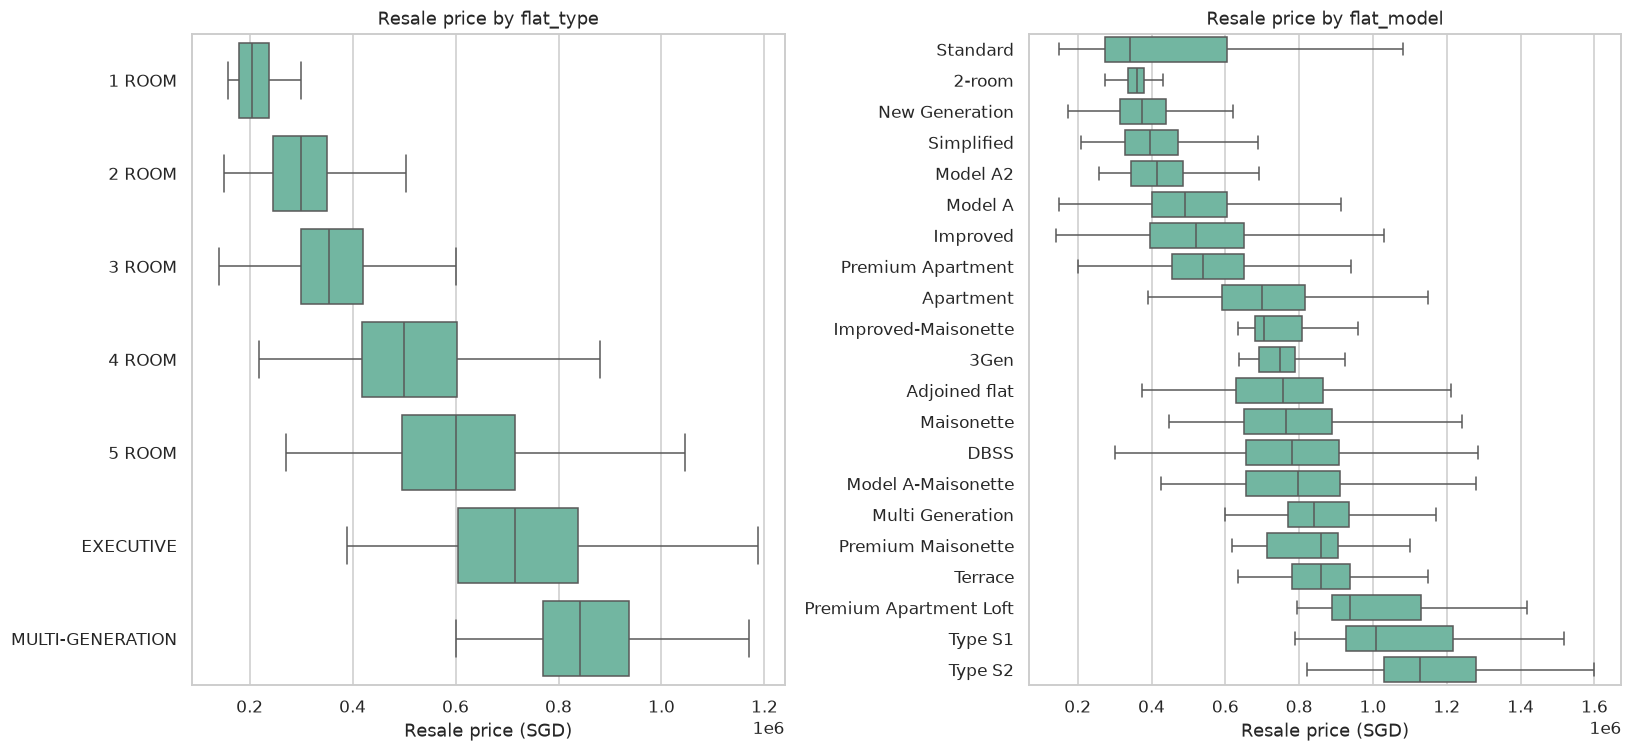

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
for column, ax in zip(category_columns, axes):
    order = df.groupby(column)["resale_price"].median().sort_values().index
    sns.boxplot(data=df, y=column, x="resale_price", order=order, showfliers=False, ax=ax)
    ax.set(title=f"Resale price by {column}", xlabel="Resale price (SGD)", ylabel="")
plt.tight_layout()
plt.show()

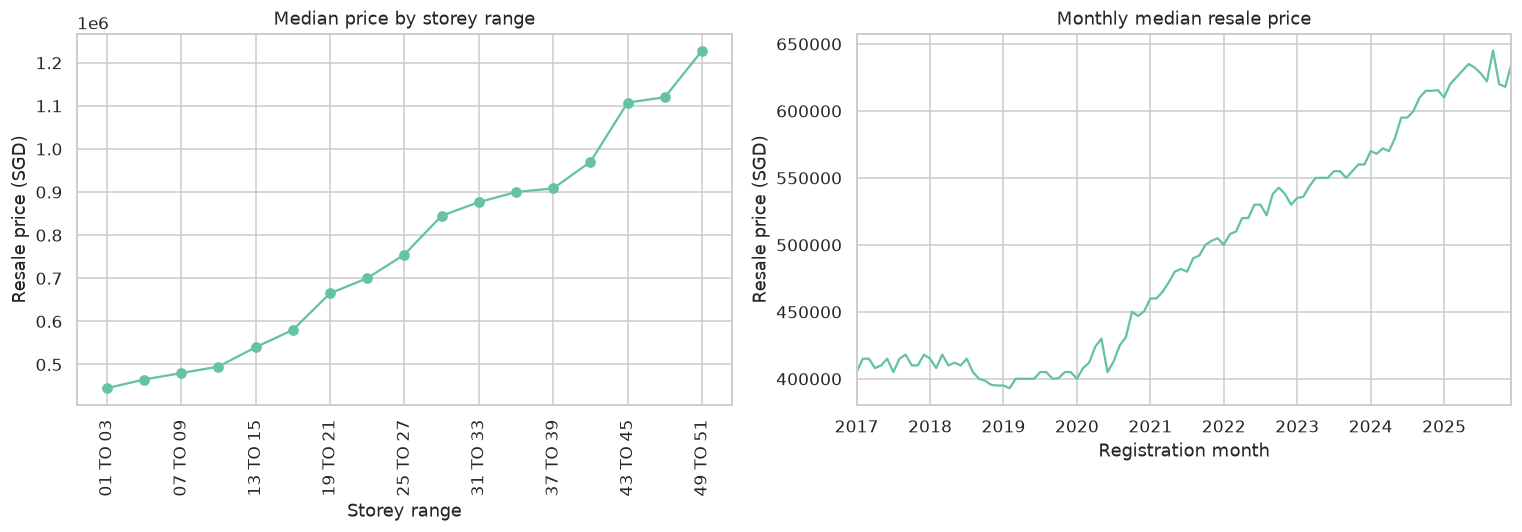

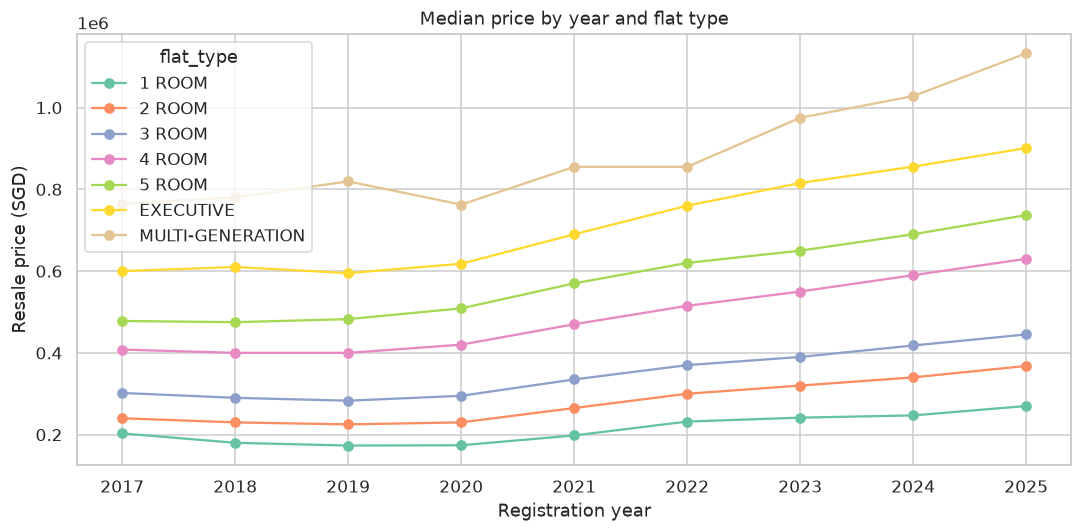

In [25]:
storey_price = df.groupby("storey_range")["resale_price"].median().reindex(storey_order)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
storey_price.plot(marker="o", ax=axes[0])
axes[0].set(title="Median price by storey range", xlabel="Storey range", ylabel="Resale price (SGD)")
axes[0].tick_params(axis="x", rotation=90)
monthly["median_price"].plot(ax=axes[1])
axes[1].set(title="Monthly median resale price", xlabel="Registration month", ylabel="Resale price (SGD)")
plt.tight_layout()
plt.show()

year_type_prices = df.pivot_table(
    index="transaction_year", columns="flat_type", values="resale_price", aggfunc="median"
)
fig, ax = plt.subplots(figsize=(10, 5))
year_type_prices.plot(marker="o", ax=ax)
ax.set(title="Median price by year and flat type", xlabel="Registration year", ylabel="Resale price (SGD)")
plt.tight_layout()
plt.show()

### 12.1 Geographic overview

Map transaction shares and median prices using GeoPandas. Gray polygons have no matched transaction statistics, rather than zero prices. Values come from original HDB town labels and are placed on planning-area proxy polygons; `KALLANG/WHAMPOA` and `CENTRAL AREA` use the mappings stated in Section 7. No allocation of transactions to individual planning subareas is inferred.

Town transaction shares reflect sample composition, not housing stock or population. Median-price differences are unadjusted for flat type, area, lease, or time. The basemap is a fixed 2019 planning geography used across the study period, not a reconstruction of historical town boundaries. [GeoPandas mapping documentation](https://geopandas.org/en/stable/docs/user_guide/mapping.html).

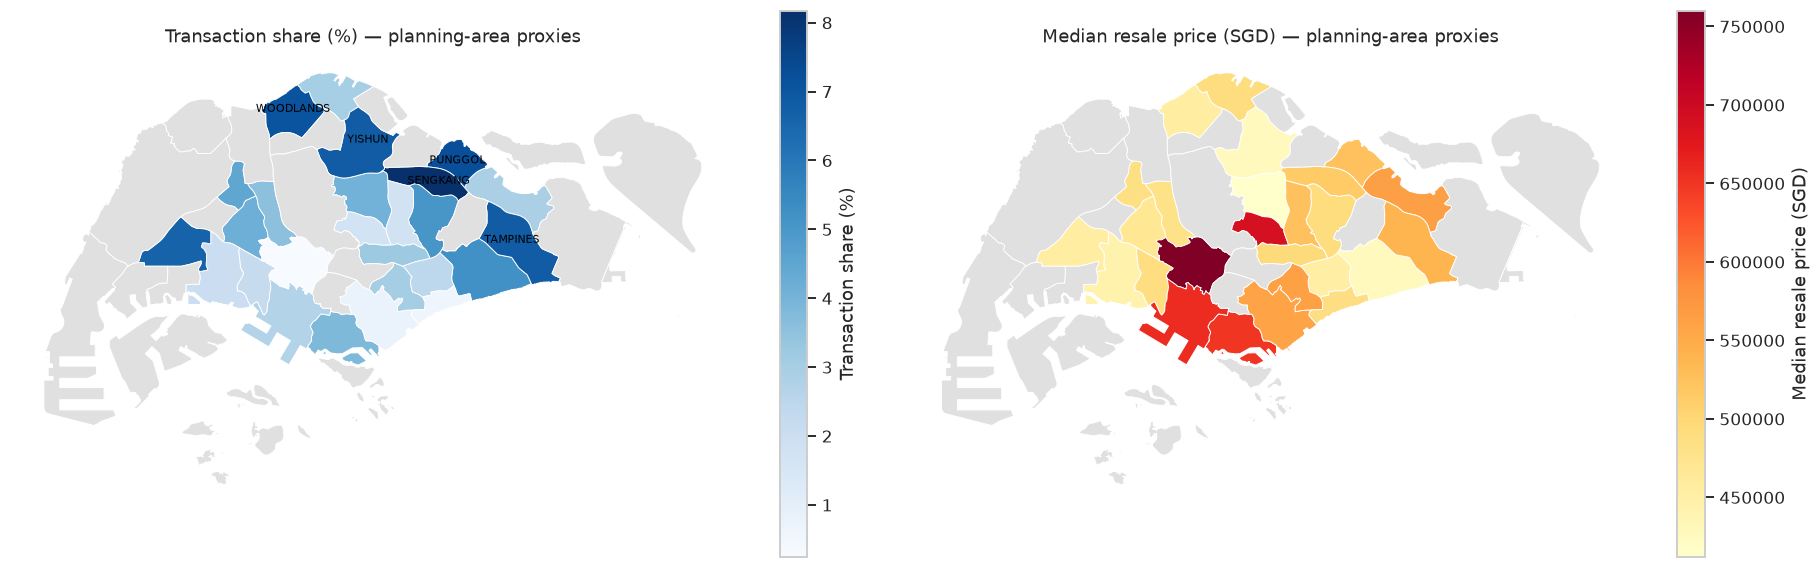

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(17, 8))
for column, cmap, title, ax in zip(
    ["share_pct", "median_price"], ["Blues", "YlOrRd"],
    ["Transaction share (%)", "Median resale price (SGD)"], axes,
):
    town_map.plot(column=column, cmap=cmap, legend=True, ax=ax,
                  edgecolor="white", linewidth=.6,
                  missing_kwds={"color": "#e0e0e0"},
                  legend_kwds={"shrink": .65, "label": title})
    ax.set_title(f"{title} — planning-area proxies")
    ax.set_axis_off()

for _, row in town_map.nlargest(5, "transactions").iterrows():
    point = row.geometry.representative_point()
    axes[0].annotate(row["map_town"], (point.x, point.y), fontsize=7,
                     ha="center", color="black")
plt.tight_layout()
plt.show()

## 13. Research questions and hedonic regression setup

**Main question:** How do differences in HDB town prices change after controlling for registration time, floor area, flat type/model, storey, and remaining lease?

**Supporting question:** Does the negative lease-price association observed for EXECUTIVE flats persist after those controls?

Use ordinary least squares (OLS) with `log(resale_price)` as the outcome. The main explanatory regressions use the same cleaned 2017–2025 sample and the same reference town, BEDOK. They describe conditional associations, not causal effects: renovation, views, precise accessibility, and buyer characteristics are unobserved. The separate forecasting experiment uses past data only.

References: [statsmodels formula interface](https://www.statsmodels.org/stable/example_formulas.html), [cluster covariance](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.get_robustcov_results.html), and [hedonic housing research on correlated unobserved attributes](https://www.nber.org/papers/w15724).

Town indicators provide interpretable town-specific premiums. Historical target encoding is reserved for a prediction comparison. Building-level indicators are not added alongside Town because buildings are nested within towns and would absorb the town indicators.

In [27]:
import statsmodels.api as sm
import patsy
from IPython.display import Markdown


def regression_data(data):
    """Create readable regression fields without changing the supplied sample."""
    columns = list(raw.columns) + ["transaction_year", "month_index", "storey_ordinal", "remaining_lease_years"]
    result = data[columns].copy()
    for column in ["town", "flat_type", "flat_model", "storey_range", "month", "block", "street_name"]:
        result[column] = result[column].astype(str)
    result["log_price"] = np.log(result["resale_price"])
    result["log_area"] = np.log(result["floor_area_sqm"])
    result["lease_10"] = (result["remaining_lease_years"] - 70) / 10
    result["time_years"] = (result["month_index"] - 48) / 12
    result["calendar_month"] = result["month_index"].mod(12) + 1
    result["building_id"] = result[["town", "street_name", "block"]].agg(" | ".join, axis=1)
    return result


hedonic = regression_data(df)
TOWN = "C(town, Treatment(reference='BEDOK'))"
TIME = "C(month)"
TYPE = "C(flat_type, Treatment(reference='4 ROOM'))"
MODEL = "C(flat_model, Treatment(reference='Model A'))"
STOREY = "C(storey_range, Treatment(reference='01 TO 03'))"
REDUNDANT_MODEL = f"{MODEL}[T.Multi Generation]"


def fit_hedonic(formula, data, clustered=True):
    """Fit OLS, omitting the model indicator absorbed by its identical flat type."""
    outcome, design = patsy.dmatrices(formula, data, return_type="dataframe")
    design_info = design.design_info
    if REDUNDANT_MODEL in design.columns:
        design = design.drop(columns=REDUNDANT_MODEL)
    model = sm.OLS(outcome.iloc[:, 0], design)
    if clustered:
        fit = model.fit(method="qr", cov_type="cluster", use_t=True,
                        cov_kwds={"groups": data.loc[design.index, "building_id"]})
    else:
        fit = model.fit(method="qr")
    assert fit.model.rank == design.shape[1]
    return fit, design_info


def predict_log(fit, design_info, data):
    design = patsy.build_design_matrices([design_info], data, return_type="dataframe")[0]
    return pd.Series(fit.predict(design[fit.params.index]), index=data.index)


display(pd.Series({
    "explanatory_rows": len(hedonic),
    "towns": hedonic["town"].nunique(),
    "registration_months": hedonic["month"].nunique(),
    "building_clusters": hedonic["building_id"].nunique(),
}, name="Regression sample").to_frame())

,Regression sample
explanatory_rows,221938
towns,26
registration_months,108
building_clusters,9670


## 14. Sequential control models

All explanatory models use the same rows and `log_price`. Month indicators absorb shared market changes; log area gives an area elasticity; the centered lease variable measures ten-year increments. Storey intervals enter as categories, so the model does not require a constant increment per ordinal step.

| Model | Added controls | Interpretation of the comparison |
|---|---|---|
| M0 | Town only | Unadjusted differences in mean log prices |
| M1 | Registration month | Differences after market-time composition |
| M2 | Log floor area | Differences after size composition |
| M3 | Flat type and model | Differences after housing-type composition |
| M4 | Storey interval and lease | Main adjusted specification |
| M5 | Lease squared and lease × flat type | Nonlinearity and heterogeneous lease associations |

`MULTI-GENERATION` and `Multi Generation` identify the same records. Its model indicator is therefore omitted while retaining its flat-type indicator. The design rank is checked before interpreting results. Model coefficients for some rare categories can remain imprecise. Standard errors are clustered by the three-field building address; these account for within-building dependence but do not establish causal identification.

In [28]:
formulas = {
    "M0": f"log_price ~ {TOWN}",
    "M1": f"log_price ~ {TOWN} + {TIME}",
    "M2": f"log_price ~ {TOWN} + {TIME} + log_area",
    "M3": f"log_price ~ {TOWN} + {TIME} + log_area + {TYPE} + {MODEL}",
    "M4": f"log_price ~ {TOWN} + {TIME} + log_area + {TYPE} + {MODEL} + {STOREY} + lease_10",
}
formulas["M5"] = formulas["M4"] + f" + I(lease_10 ** 2) + lease_10:{TYPE}"
main_fits = {}
main_info = {}
for name, formula in formulas.items():
    main_fits[name], main_info[name] = fit_hedonic(formula, hedonic)
    print(f"{name}: {int(main_fits[name].nobs):,} rows, {len(main_fits[name].params)} coefficients")

model_comparison = pd.DataFrame({
    name: {
        "rows": fit.nobs,
        "coefficients": len(fit.params),
        "adjusted_R2": fit.rsquared_adj,
        "in_sample_log_RMSE": np.sqrt(np.mean(fit.resid ** 2)),
        "AIC": fit.aic,
    }
    for name, fit in main_fits.items()
}).T
assert model_comparison["rows"].eq(len(hedonic)).all()
display(model_comparison)

M0: 221,938 rows, 26 coefficients


M1: 221,938 rows, 133 coefficients


M2: 221,938 rows, 134 coefficients


M3: 221,938 rows, 159 coefficients


M4: 221,938 rows, 176 coefficients


M5: 221,938 rows, 183 coefficients


,rows,coefficients,adjusted_R2,in_sample_log_RMSE,AIC
M0,221938.000,26.000,0.084,0.332,140371.670
M1,221938.000,133.000,0.276,0.295,88279.126
M2,221938.000,134.000,0.746,0.175,-143930.123
M3,221938.000,159.000,0.837,0.140,-242600.786
M4,221938.000,176.000,0.918,0.099,-394458.110
M5,221938.000,183.000,0.919,0.099,-397312.344


## 15. Town premiums before and after controls

Convert each town coefficient and its confidence limits to `100 × (exp(coefficient) - 1)`. Every value is relative to BEDOK; the reference is normalized to zero, not estimated to have zero uncertainty relative to all other towns.

M0 compares geometric price levels, while M4 compares conditional log-price levels. These are not arithmetic median-price comparisons. A reduced premium after controls indicates that measured housing/time composition contributes to the unadjusted difference; the change is not a causal decomposition. Rankings and the size of changes are descriptive, especially where town housing profiles have limited overlap.

,M0,M1,M2,M3,M4,M5
town,,,,,,
BEDOK,0.000,0.000,0.000,0.000,0.000,0.000
ANG MO KIO,-1.747,-1.601,2.891,5.021,1.897,2.212
BISHAN,50.186,51.731,26.309,21.033,20.916,20.923
BUKIT BATOK,4.666,0.839,-4.035,-9.363,-13.943,-13.800
BUKIT MERAH,29.863,29.237,33.363,29.504,22.547,22.922
BUKIT PANJANG,7.175,8.120,-5.736,-14.409,-18.890,-18.723
BUKIT TIMAH,63.011,64.656,35.513,37.179,41.121,41.199
CENTRAL AREA,38.526,38.919,51.991,28.687,32.285,32.808
CHOA CHU KANG,5.424,4.243,-14.695,-20.460,-24.658,-24.445


,premium_pct_M0,low_pct_M0,high_pct_M0,premium_pct_M4,low_pct_M4,high_pct_M4,change_pp,rank_M0,rank_M4
town,,,,,,,,,
PASIR RIS,25.942,21.387,30.669,-12.473,-13.349,-11.588,-38.415,6.000,17.000
PUNGGOL,17.389,13.306,21.619,-17.180,-18.089,-16.261,-34.569,10.000,20.000
SENGKANG,13.773,9.863,17.822,-19.288,-20.145,-18.423,-33.061,12.000,22.000
SEMBAWANG,7.360,2.994,11.911,-24.129,-25.068,-23.179,-31.489,16.000,25.000
CHOA CHU KANG,5.424,1.663,9.324,-24.658,-25.415,-23.893,-30.082,18.000,26.000
BISHAN,50.186,41.981,58.866,20.916,19.234,22.621,-29.271,2.000,6.000
BUKIT PANJANG,7.175,2.925,11.600,-18.890,-19.946,-17.820,-26.065,17.000,21.000
WOODLANDS,1.502,-2.189,5.333,-23.172,-23.881,-22.457,-24.675,21.000,24.000
TAMPINES,19.795,15.465,24.288,-4.125,-4.991,-3.251,-23.920,8.000,14.000


,transactions,median_area,median_lease,median_price,five_room_share_pct,executive_share_pct
town,,,,,,
BEDOK,11555,88.000,59.583,428000.000,18.122,4.976
PASIR RIS,6393,122.000,71.750,565000.000,31.550,25.575
PUNGGOL,16146,93.000,92.083,525944.000,31.643,1.864
SENGKANG,18140,94.000,87.292,515000.000,34.135,6.202
SEMBAWANG,6705,95.000,82.750,490000.000,29.963,10.529


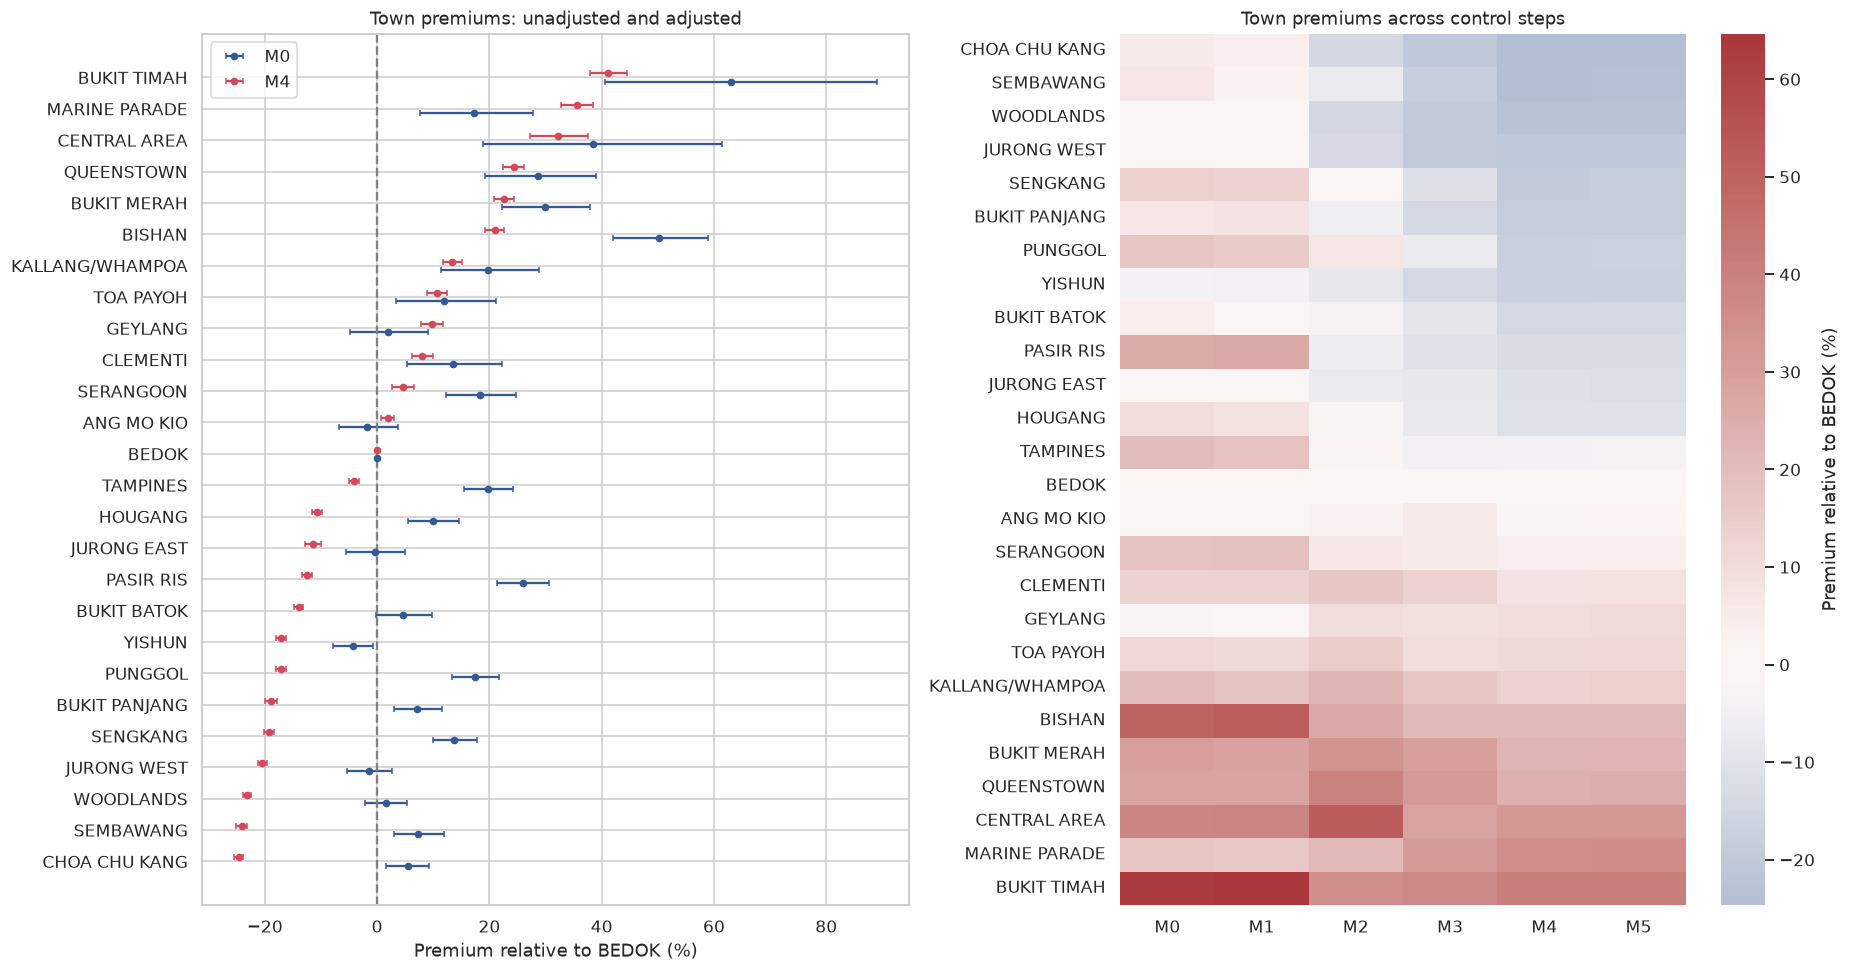

In [29]:
def town_effects(fit):
    confidence = fit.conf_int()
    rows = [{"town": "BEDOK", "premium_pct": 0., "low_pct": 0., "high_pct": 0.}]
    for term in fit.params.index:
        if term.startswith(TOWN + "[T."):
            rows.append({
                "town": term.split("[T.")[1][:-1],
                "premium_pct": 100 * np.expm1(fit.params[term]),
                "low_pct": 100 * np.expm1(confidence.loc[term, 0]),
                "high_pct": 100 * np.expm1(confidence.loc[term, 1]),
            })
    return pd.DataFrame(rows).set_index("town")


regional_effects = {name: town_effects(fit) for name, fit in main_fits.items()}
regional_path = pd.DataFrame({name: table["premium_pct"] for name, table in regional_effects.items()})
regional_change = regional_effects["M0"].add_suffix("_M0").join(regional_effects["M4"].add_suffix("_M4"))
regional_change["change_pp"] = regional_change["premium_pct_M4"] - regional_change["premium_pct_M0"]
regional_change["rank_M0"] = regional_change["premium_pct_M0"].rank(ascending=False, method="min")
regional_change["rank_M4"] = regional_change["premium_pct_M4"].rank(ascending=False, method="min")
regional_change = regional_change.loc[regional_change["change_pp"].abs().sort_values(ascending=False).index]
display(regional_path)
display(regional_change)

profile_towns = ["BEDOK"] + regional_change.index[:4].tolist()
town_profiles = hedonic.loc[hedonic["town"].isin(profile_towns)].groupby("town").agg(
    transactions=("resale_price", "size"),
    median_area=("floor_area_sqm", "median"),
    median_lease=("remaining_lease_years", "median"),
    median_price=("resale_price", "median"),
    five_room_share_pct=("flat_type", lambda s: 100 * s.eq("5 ROOM").mean()),
    executive_share_pct=("flat_type", lambda s: 100 * s.eq("EXECUTIVE").mean()),
).reindex(profile_towns)
display(town_profiles)

order = regional_effects["M4"]["premium_pct"].sort_values().index
fig, axes = plt.subplots(1, 2, figsize=(17, 9))
for name, offset, color in [("M0", -.13, "#345995"), ("M4", .13, "#d1495b")]:
    effects = regional_effects[name].reindex(order)
    y = np.arange(len(order)) + offset
    axes[0].errorbar(effects["premium_pct"], y,
                    xerr=[effects["premium_pct"] - effects["low_pct"], effects["high_pct"] - effects["premium_pct"]],
                    fmt="o", markersize=4, capsize=2, color=color, label=name)
axes[0].set_yticks(np.arange(len(order)), order)
axes[0].axvline(0, color="gray", linestyle="--")
axes[0].set(title="Town premiums: unadjusted and adjusted", xlabel="Premium relative to BEDOK (%)")
axes[0].legend()
sns.heatmap(regional_path.reindex(order), cmap="vlag", center=0, ax=axes[1],
            cbar_kws={"label": "Premium relative to BEDOK (%)"})
axes[1].set(title="Town premiums across control steps", ylabel="")
plt.tight_layout()
plt.show()

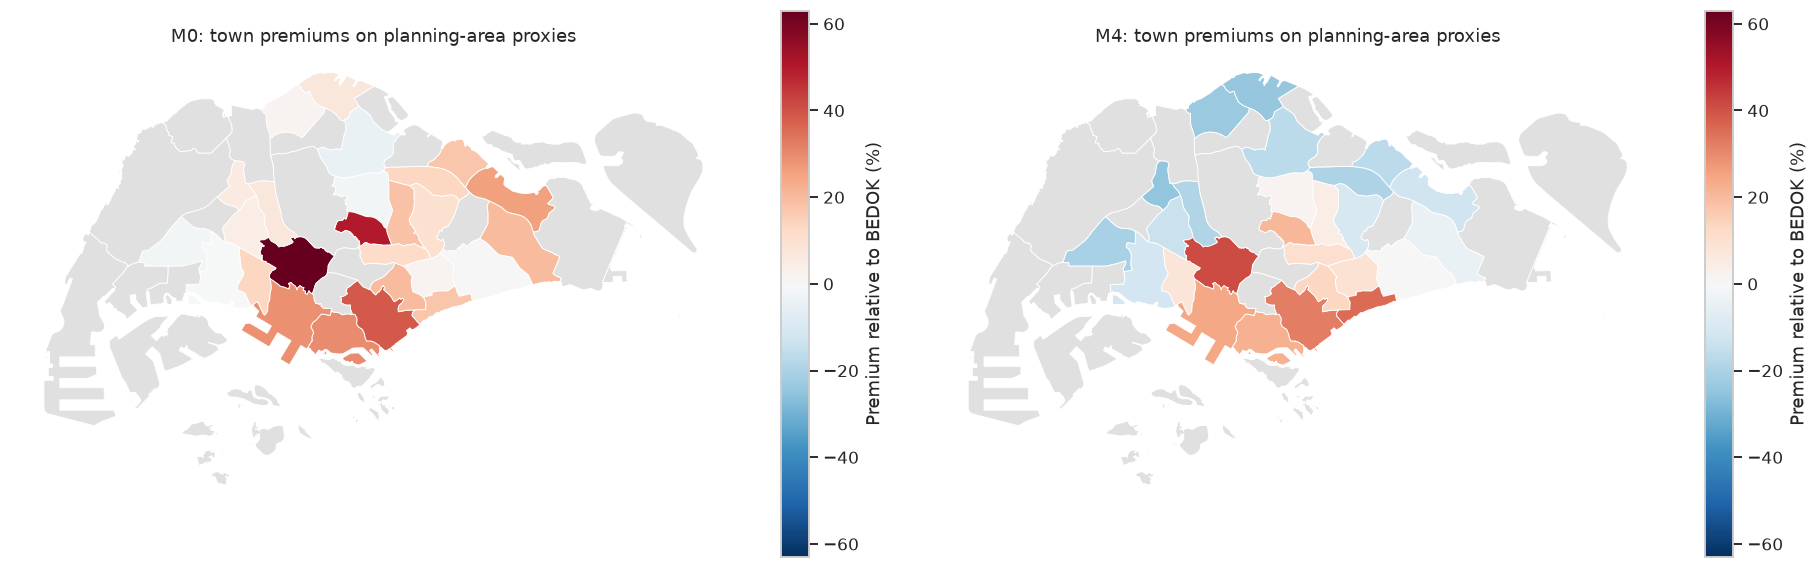

In [30]:
premium_map = town_boundaries.merge(regional_path[["M0", "M4"]], left_on="map_town", right_index=True, how="left")
limit = np.abs(regional_path[["M0", "M4"]].to_numpy()).max()
fig, axes = plt.subplots(1, 2, figsize=(17, 8))
for name, ax in zip(["M0", "M4"], axes):
    premium_map.plot(column=name, cmap="RdBu_r", vmin=-limit, vmax=limit,
                     legend=True, ax=ax, edgecolor="white", linewidth=.6,
                     missing_kwds={"color": "#e0e0e0"},
                     legend_kwds={"label": "Premium relative to BEDOK (%)", "shrink": .65})
    ax.set_title(f"{name}: town premiums on planning-area proxies")
    ax.set_axis_off()
plt.tight_layout()
plt.show()

## 16. Housing characteristics and the EXECUTIVE lease pattern

For log area, the coefficient is an elasticity. For a linear `lease_10` term, `100 × (exp(coefficient) - 1)` is the conditional ten-year price difference. In M5 it refers to the reference flat type at the centered lease value; interaction and squared terms must be considered together.

Fit the same EXECUTIVE sample with successively richer controls. This tests whether its negative bivariate lease association persists after time, town, area, model, and storey controls. A coefficient moving towards zero supports a composition explanation, while any remaining coefficient is still an observational association.

### 16.1 Adjusted categorical contrasts and time profile

The M4 categorical coefficients compare each label with its stated reference, conditional on the other controls. Sample counts help identify sparse labels. Some hypothetical combinations of area, type, and model have little empirical support. The MULTI-GENERATION flat-type coefficient absorbs its identical model label and is a combined category contrast.

Storey contrasts do not impose a constant increase per interval. The registration-month index is a conditional nominal-price profile normalized to January 2017; it does not identify inflation or a causal market index.

M4 adjusted contrasts: flat_type


,rows_with_label,difference_pct,low_pct,high_pct
label,,,,
1 ROOM,80,3.497,-0.445,7.595
2 ROOM,4492,-2.684,-5.165,-0.139
3 ROOM,52836,-2.130,-3.245,-1.001
5 ROOM,54483,3.738,2.601,4.887
EXECUTIVE,15933,4.515,2.617,6.448
MULTI-GENERATION,84,31.510,24.503,38.912


M4 adjusted contrasts: flat_model


,rows_with_label,difference_pct,low_pct,high_pct
label,,,,
2-room,362,1.159,-0.878,3.237
3Gen,66,-9.841,-12.426,-7.179
Adjoined flat,378,13.080,11.220,14.972
Apartment,7980,9.097,7.447,10.773
DBSS,3556,20.639,19.297,21.997
Improved,54249,-1.292,-2.032,-0.546
Improved-Maisonette,30,40.104,35.907,44.430
Maisonette,6113,15.561,13.720,17.433
Model A-Maisonette,388,21.149,15.791,26.754


M4 adjusted contrasts: storey_range


,rows_with_label,difference_pct,low_pct,high_pct
label,,,,
04 TO 06,50919,3.721,3.574,3.869
07 TO 09,46557,6.646,6.474,6.818
10 TO 12,41453,8.400,8.210,8.589
13 TO 15,21370,10.186,9.933,10.441
16 TO 18,10002,13.091,12.693,13.490
19 TO 21,4302,17.771,17.115,18.431
22 TO 24,3017,19.565,18.677,20.459
25 TO 27,1876,21.591,20.528,22.664
28 TO 30,1216,24.575,23.311,25.852


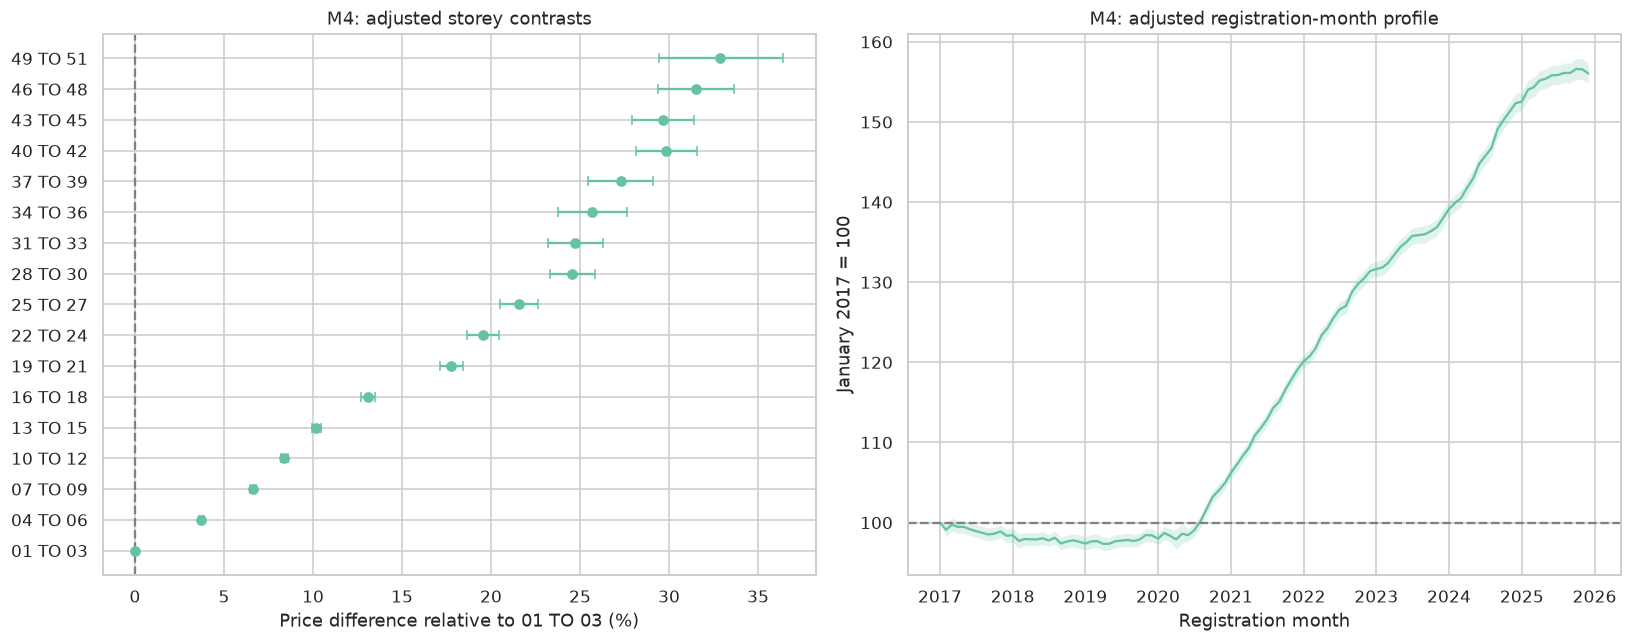

In [31]:
housing_category_rows = []
main = main_fits["M4"]
confidence = main.conf_int()
for field, prefix in [("flat_type", TYPE), ("flat_model", MODEL), ("storey_range", STOREY)]:
    for term in main.params.index:
        if term.startswith(prefix + "[T."):
            label = term.split("[T.")[1][:-1]
            housing_category_rows.append({
                "field": field, "label": label,
                "rows_with_label": int(hedonic[field].eq(label).sum()),
                "difference_pct": 100 * np.expm1(main.params[term]),
                "low_pct": 100 * np.expm1(confidence.loc[term, 0]),
                "high_pct": 100 * np.expm1(confidence.loc[term, 1]),
            })
housing_category_effects = pd.DataFrame(housing_category_rows)
for field, table in housing_category_effects.groupby("field", sort=False):
    print(f"M4 adjusted contrasts: {field}")
    display(table.drop(columns="field").set_index("label"))

storey_effects = housing_category_effects.loc[housing_category_effects["field"].eq("storey_range")].set_index("label")
storey_effects = storey_effects.reindex(storey_order)
storey_effects.loc["01 TO 03", ["difference_pct", "low_pct", "high_pct"]] = 0.
month_rows = [{"month": "2017-01", "index": 100., "low": 100., "high": 100.}]
for term in main.params.index:
    if term.startswith(TIME + "[T."):
        month_rows.append({"month": term.split("[T.")[1][:-1],
                           "index": 100 * np.exp(main.params[term]),
                           "low": 100 * np.exp(confidence.loc[term, 0]),
                           "high": 100 * np.exp(confidence.loc[term, 1])})
adjusted_month_index = pd.DataFrame(month_rows).sort_values("month")
adjusted_month_index["date"] = pd.to_datetime(adjusted_month_index["month"])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].errorbar(storey_effects["difference_pct"], np.arange(len(storey_order)),
                xerr=[storey_effects["difference_pct"] - storey_effects["low_pct"],
                      storey_effects["high_pct"] - storey_effects["difference_pct"]],
                fmt="o", capsize=3)
axes[0].set_yticks(np.arange(len(storey_order)), storey_order)
axes[0].axvline(0, color="gray", linestyle="--")
axes[0].set(title="M4: adjusted storey contrasts", xlabel="Price difference relative to 01 TO 03 (%)")
axes[1].plot(adjusted_month_index["date"], adjusted_month_index["index"])
axes[1].fill_between(adjusted_month_index["date"], adjusted_month_index["low"], adjusted_month_index["high"], alpha=.2)
axes[1].axhline(100, color="gray", linestyle="--")
axes[1].set(title="M4: adjusted registration-month profile", xlabel="Registration month", ylabel="January 2017 = 100")
plt.tight_layout()
plt.show()

### 16.2 Area elasticity and the EXECUTIVE lease investigation

The coefficient table tracks area and lease associations across the main specifications. The EXECUTIVE regressions then use the same subset and add time, town, and housing controls in sequence. Its model-category reference is Apartment, which is observed within this flat type.

,model,term,coefficient,low,high
0,M2,log_area,0.982,0.967,0.996
1,M3,log_area,0.096,0.049,0.144
2,M4,log_area,0.811,0.778,0.844
3,M4,lease_10,0.099,0.097,0.101
4,M5,log_area,0.778,0.744,0.811
5,M5,lease_10,0.102,0.099,0.105
6,M5,I(lease_10 ** 2),-0.003,-0.004,-0.001


,rows,lease_10_coefficient,ten_year_difference_pct,low_pct,high_pct
model,,,,,
E0: lease,15933.000,-0.184,-16.792,-17.846,-15.725
E1: + time,15933.000,-0.114,-10.753,-12.038,-9.449
E2: + town,15933.000,-0.008,-0.831,-2.344,0.704
E3: + housing,15933.000,0.055,5.605,3.950,7.286


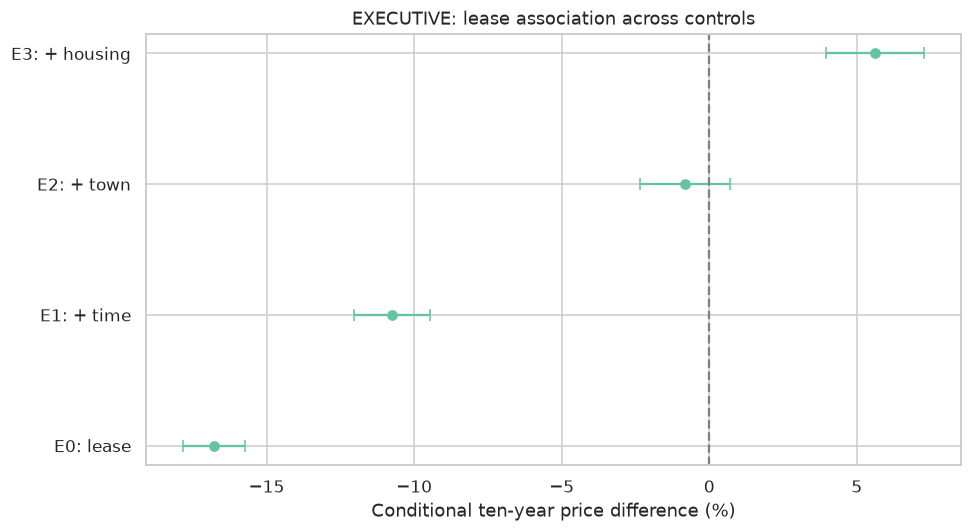

In [32]:
characteristic_rows = []
for name, fit in main_fits.items():
    ci = fit.conf_int()
    for term in ["log_area", "lease_10", "I(lease_10 ** 2)"]:
        if term in fit.params.index:
            characteristic_rows.append({"model": name, "term": term,
                                        "coefficient": fit.params[term],
                                        "low": ci.loc[term, 0], "high": ci.loc[term, 1]})
display(pd.DataFrame(characteristic_rows))

executive = hedonic.loc[hedonic["flat_type"].eq("EXECUTIVE")]
executive_formulas = {
    "E0: lease": "log_price ~ lease_10",
    "E1: + time": f"log_price ~ lease_10 + {TIME}",
    "E2: + town": f"log_price ~ lease_10 + {TIME} + {TOWN}",
    "E3: + housing": f"log_price ~ lease_10 + {TIME} + {TOWN} + log_area + C(flat_model, Treatment(reference='Apartment')) + {STOREY}",
}
executive_rows = []
for name, formula in executive_formulas.items():
    fit, _ = fit_hedonic(formula, executive)
    ci = fit.conf_int().loc["lease_10"]
    executive_rows.append({"model": name, "rows": fit.nobs,
                           "lease_10_coefficient": fit.params["lease_10"],
                           "ten_year_difference_pct": 100 * np.expm1(fit.params["lease_10"]),
                           "low_pct": 100 * np.expm1(ci.iloc[0]),
                           "high_pct": 100 * np.expm1(ci.iloc[1])})
executive_results = pd.DataFrame(executive_rows).set_index("model")
display(executive_results)

fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(executive_results["ten_year_difference_pct"], np.arange(len(executive_results)),
            xerr=[executive_results["ten_year_difference_pct"] - executive_results["low_pct"],
                  executive_results["high_pct"] - executive_results["ten_year_difference_pct"]],
            fmt="o", capsize=4)
ax.set_yticks(np.arange(len(executive_results)), executive_results.index)
ax.axvline(0, color="gray", linestyle="--")
ax.set(title="EXECUTIVE: lease association across controls", xlabel="Conditional ten-year price difference (%)")
plt.tight_layout()
plt.show()

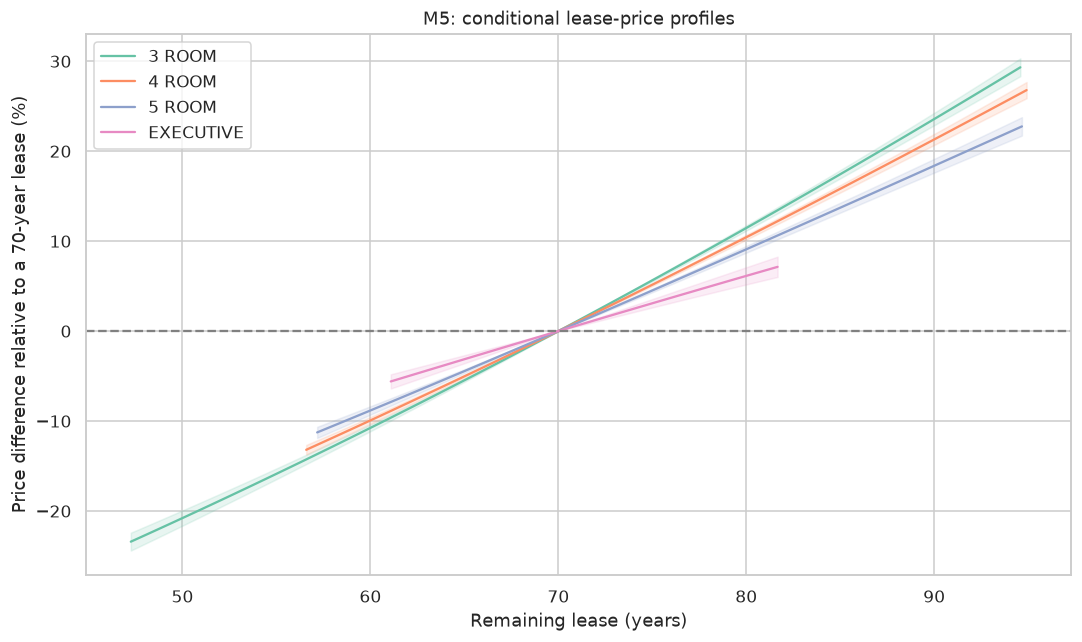

In [33]:
fit = main_fits["M5"]
fig, ax = plt.subplots(figsize=(10, 6))
for flat_type, color in zip(["3 ROOM", "4 ROOM", "5 ROOM", "EXECUTIVE"], sns.color_palette("Set2", 4)):
    part = hedonic.loc[hedonic["flat_type"].eq(flat_type), "remaining_lease_years"]
    lease_grid = np.linspace(part.quantile(.05), part.quantile(.95), 80)
    centered = (lease_grid - 70) / 10
    contrast = pd.DataFrame(0., index=np.arange(len(lease_grid)), columns=fit.params.index)
    contrast["lease_10"] = centered
    contrast["I(lease_10 ** 2)"] = centered ** 2
    if flat_type != "4 ROOM":
        interaction = f"lease_10:{TYPE}[T.{flat_type}]"
        contrast[interaction] = centered
    delta = contrast.to_numpy() @ fit.params.to_numpy()
    variance = np.einsum("ij,jk,ik->i", contrast.to_numpy(), fit.cov_params().to_numpy(), contrast.to_numpy())
    se = np.sqrt(variance)
    ax.plot(lease_grid, 100 * np.expm1(delta), color=color, label=flat_type)
    ax.fill_between(lease_grid, 100 * np.expm1(delta - 1.96 * se),
                    100 * np.expm1(delta + 1.96 * se), color=color, alpha=.15)
ax.axhline(0, color="gray", linestyle="--")
ax.set(title="M5: conditional lease-price profiles", xlabel="Remaining lease (years)",
       ylabel="Price difference relative to a 70-year lease (%)")
ax.legend()
plt.tight_layout()
plt.show()

The curves hold other model terms constant, restrict the lease range to each flat type's observed 5th–95th percentiles, and show pointwise approximate 95% confidence bands. They are conditional profiles relative to 70 years, not observed depreciation paths of individual flats. Cross-type comparisons concern profile shape rather than absolute price levels.

## 17. Diagnostics and explanatory sensitivity

Inspect log residuals, tail behavior, and town-level in-sample residual errors. Full design rank does not guarantee precise independent interpretation: area, flat type, model, and lease can be highly correlated. Confidence intervals and specification stability matter more than small p-values in this large sample.

Repeat M4 with deduplicated data, with the excluded lease records restored, and with ordinal rather than categorical storey. These comparisons describe sensitivity to the supplied sample and representation. An additional lease/storey-first intermediate model shows how the attribution of town-premium changes depends on control order; the final set of controls is unchanged.

,count,log_RMSE
town,,
PASIR RIS,6393,0.074
BUKIT BATOK,9211,0.075
PUNGGOL,16146,0.082
TAMPINES,15144,0.082
CHOA CHU KANG,10021,0.083
WOODLANDS,15743,0.084
SEMBAWANG,6705,0.087
BEDOK,11555,0.092
YISHUN,15129,0.093


,Design diagnostics
M4_design_rank,176.000
M4_design_columns,176.000
M4_condition_number,677.144


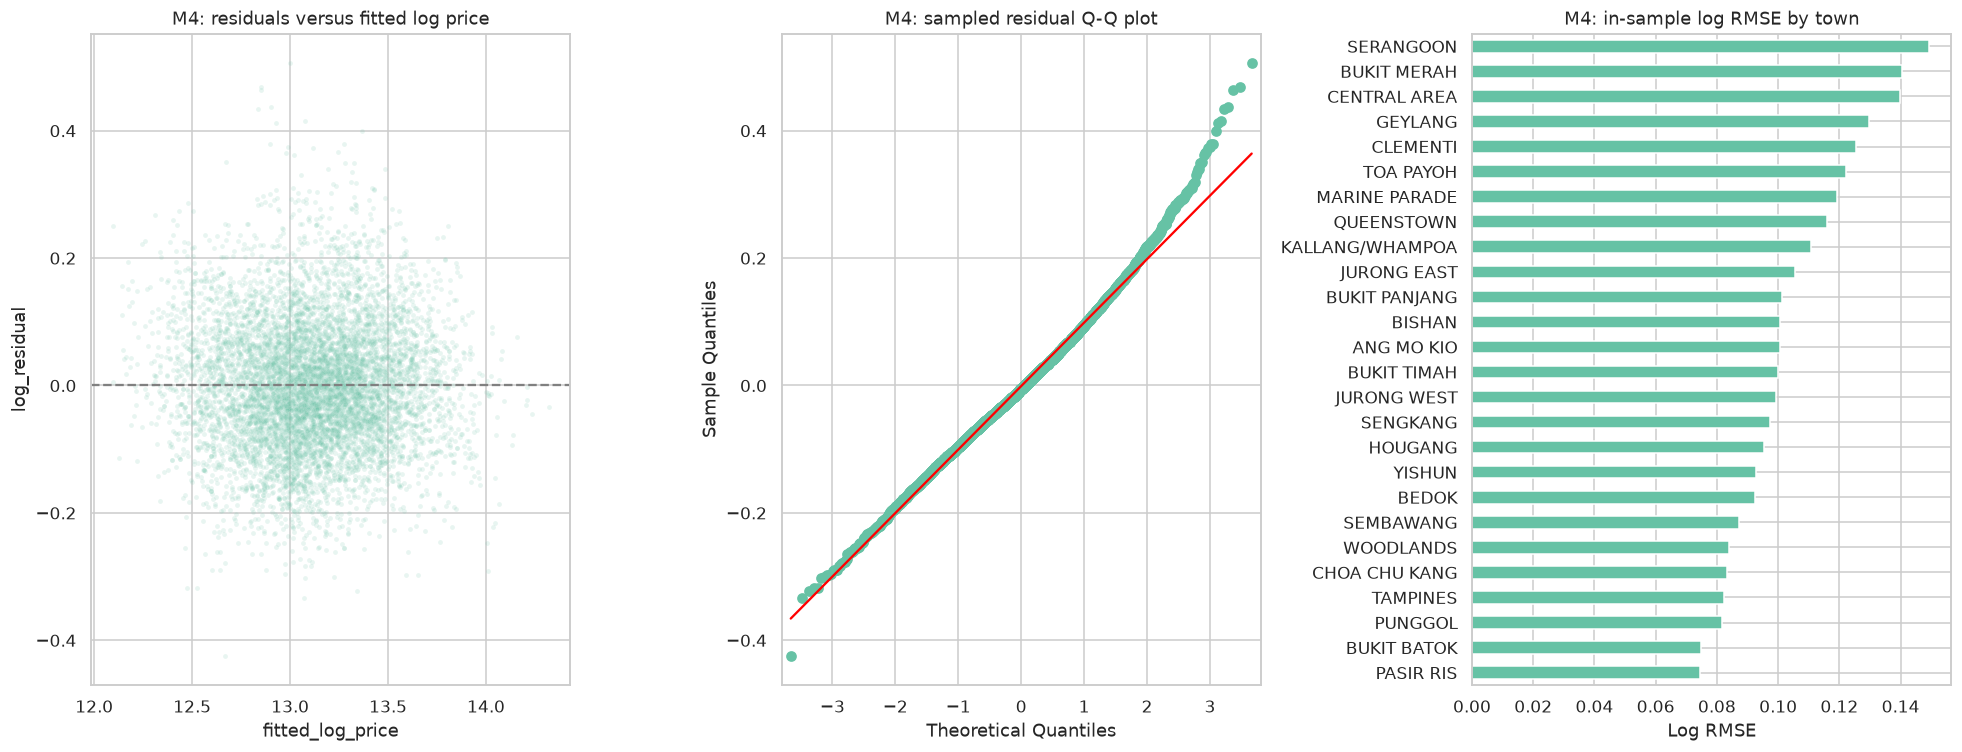

In [34]:
main = main_fits["M4"]
diagnostics = hedonic[["town", "flat_type", "resale_price"]].copy()
diagnostics["fitted_log_price"] = main.fittedvalues
diagnostics["log_residual"] = main.resid
diagnostic_sample = diagnostics.sample(8000, random_state=42)
town_residual_error = diagnostics.groupby("town")["log_residual"].agg(
    count="size", log_RMSE=lambda s: np.sqrt(np.mean(s ** 2))
).sort_values("log_RMSE")
display(town_residual_error)
display(pd.Series({
    "M4_design_rank": main.model.rank,
    "M4_design_columns": len(main.params),
    "M4_condition_number": main.condition_number,
}, name="Design diagnostics").to_frame())

fig, axes = plt.subplots(1, 3, figsize=(18, 7))
sns.scatterplot(data=diagnostic_sample, x="fitted_log_price", y="log_residual", alpha=.15, s=10, ax=axes[0])
axes[0].axhline(0, color="gray", linestyle="--")
axes[0].set_title("M4: residuals versus fitted log price")
sm.qqplot(diagnostic_sample["log_residual"], line="s", ax=axes[1])
axes[1].set_title("M4: sampled residual Q-Q plot")
town_residual_error["log_RMSE"].plot.barh(ax=axes[2])
axes[2].set(title="M4: in-sample log RMSE by town", xlabel="Log RMSE", ylabel="")
plt.tight_layout()
plt.show()

In [35]:
all_valid = regression_data(pd.concat([df, lease_excluded]).sort_index())
explanatory_variants = {
    "M4: main": (formulas["M4"], hedonic),
    "M4: deduplicated": (formulas["M4"], hedonic.loc[~hedonic.duplicated(subset=list(raw.columns))]),
    "M4: lease flags retained": (formulas["M4"], all_valid),
    "M4: ordinal storey": (formulas["M4"].replace(STOREY, "storey_ordinal"), hedonic),
}
sensitivity_rows = []
for name, (formula, sample_data) in explanatory_variants.items():
    fit = main if name == "M4: main" else fit_hedonic(formula, sample_data)[0]
    premiums = town_effects(fit)["premium_pct"]
    sensitivity_rows.append({
        "variant": name, "rows": fit.nobs, "area_elasticity": fit.params["log_area"],
        "lease_ten_year_pct": 100 * np.expm1(fit.params["lease_10"]),
        "max_town_change_vs_M4_pp": (premiums - regional_path["M4"]).abs().max(),
    })
display(pd.DataFrame(sensitivity_rows).set_index("variant"))

lease_first_formula = f"log_price ~ {TOWN} + {TIME} + {STOREY} + lease_10"
lease_first, _ = fit_hedonic(lease_first_formula, hedonic)
control_order = regional_path[["M1", "M2", "M4"]].copy()
control_order["lease_storey_first"] = town_effects(lease_first)["premium_pct"]
display(control_order.loc[regional_change.index[:8]])

,rows,area_elasticity,lease_ten_year_pct,max_town_change_vs_M4_pp
variant,,,,
M4: main,221938.000,0.811,10.390,0.000
M4: deduplicated,221629.000,0.811,10.392,0.093
M4: lease flags retained,222066.000,0.811,10.390,0.012
M4: ordinal storey,221938.000,0.811,10.343,0.358


,M1,M2,M4,lease_storey_first
town,,,,
PASIR RIS,26.497,-6.246,-12.473,14.241
PUNGGOL,16.030,7.433,-17.180,-14.428
SENGKANG,13.285,1.124,-19.288,-13.807
SEMBAWANG,2.944,-6.930,-24.129,-19.525
CHOA CHU KANG,4.243,-14.695,-24.658,-12.220
BISHAN,51.731,26.309,20.916,43.412
BUKIT PANJANG,8.120,-5.736,-18.890,-10.864
WOODLANDS,0.749,-14.679,-23.172,-12.522


## 18. Chronological prediction and preparation comparisons

Month fixed effects serve explanatory estimation over observed months; they cannot estimate a coefficient for a future month. Forecasting therefore uses a continuous time trend plus calendar-month indicators. Select a linear or quadratic trend using 2024 validation MAE, without using 2025 to choose it.

Use 2018–2023 to fit the validation models, 2024 to validate, and 2018–2024 to refit the final models before testing on 2025. All preparation variants use the same cleaned training/test rows; 2017 supplies historical address priors only so that target-encoded and non-target-encoded variants remain comparable. The main evaluation population excludes the lease flags under the stated rule, and test records are not selected using price-tail thresholds.

**Minimal preparation** here means the transformations needed for a usable OLS baseline: parse lease/time/storey and encode town/flat type, with a common log-price outcome. **Systematic preparation** then changes one step at a time:

| Variant | Change from the previous variant |
|---|---|
| P0 | Baseline: raw area, ordinal storey, linear lease, town/type indicators |
| P1 | Log area |
| P2 | Flat model controls, omitting the exact redundant indicator |
| P3 | Categorical storey |
| P4 | Quadratic lease term |
| P5 | Log historical hierarchical address encoding |

P0 and P5 use the same OLS approach and evaluation records. The address encoder uses only earlier years for every training row; the 2025 encoder uses no 2025 prices. Category vocabularies are learned from each training sample. The categories in this snapshot are already present in both relevant training periods.

Use a global training-residual smearing factor to convert log predictions to SGD: `exp(predicted_log_price) × mean(exp(training_residual))`. This is an approximate mean-price correction and need not remove conditional retransformation bias under heteroscedasticity. Report both log errors and SGD errors.

In [36]:
forecast = hedonic.loc[hedonic["transaction_year"].ge(2018)].copy()
forecast["log_address_te"] = np.log(address_encoding.loc[forecast.index, "address_te"])
assert forecast["log_address_te"].notna().all()

development = forecast.loc[forecast["transaction_year"].le(2023)]
validation = forecast.loc[forecast["transaction_year"].eq(2024)]
training = forecast.loc[forecast["transaction_year"].le(2024)]
test = forecast.loc[forecast["transaction_year"].eq(2025)]
for column in ["town", "flat_type", "flat_model", "storey_range"]:
    assert set(validation[column]) <= set(development[column])
    assert set(test[column]) <= set(training[column])
display(pd.DataFrame({"period": ["development", "validation", "final training", "test"],
                      "rows": [len(development), len(validation), len(training), len(test)],
                      "years": ["2018–2023", "2024", "2018–2024", "2025"]}))


def forecast_formulas(time_term):
    baseline = f"log_price ~ {TOWN} + {TYPE} + floor_area_sqm + storey_ordinal + lease_10 + {time_term}"
    specifications = {"P0": baseline}
    specifications["P1"] = baseline.replace("floor_area_sqm", "log_area")
    specifications["P2"] = specifications["P1"] + f" + {MODEL}"
    specifications["P3"] = specifications["P2"].replace("storey_ordinal", STOREY)
    specifications["P4"] = specifications["P3"] + " + I(lease_10 ** 2)"
    specifications["P5"] = specifications["P4"] + " + log_address_te"
    return specifications


def prediction_scores(actual, predicted_log, smearing):
    predicted_price = np.exp(predicted_log) * smearing
    return {
        "log_RMSE": np.sqrt(np.mean((np.log(actual) - predicted_log) ** 2)),
        "MAE_SGD": np.mean(np.abs(actual - predicted_price)),
        "RMSE_SGD": np.sqrt(np.mean((actual - predicted_price) ** 2)),
        "mean_error_SGD": np.mean(predicted_price - actual),
    }


time_candidates = {
    "linear": "time_years + C(calendar_month)",
    "quadratic": "time_years + I(time_years ** 2) + C(calendar_month)",
}
trend_validation_rows = []
for name, time_term in time_candidates.items():
    formula = forecast_formulas(time_term)["P4"]
    fit, info = fit_hedonic(formula, development, clustered=False)
    predicted_log = predict_log(fit, info, validation)
    smearing = np.exp(fit.resid).mean()
    trend_validation_rows.append({"trend": name, **prediction_scores(validation["resale_price"], predicted_log, smearing)})
trend_validation = pd.DataFrame(trend_validation_rows).set_index("trend")
selected_trend = trend_validation["MAE_SGD"].idxmin()
display(trend_validation)
print(f"Selected time trend using 2024 validation only: {selected_trend}")
prediction_formulas = forecast_formulas(time_candidates[selected_trend])

,period,rows,years
0,development,148595,2018–2023
1,validation,27812,2024
2,final training,176407,2018–2024
3,test,25022,2025


,log_RMSE,MAE_SGD,RMSE_SGD,mean_error_SGD
trend,,,,
linear,0.094,44121.562,59348.186,-9751.660
quadratic,0.123,67116.140,84994.796,56244.128


Selected time trend using 2024 validation only: linear


,training_rows,test_rows,validation_MAE_SGD,log_RMSE,MAE_SGD,RMSE_SGD,mean_error_SGD
variant,,,,,,,
P0,176407,25022,47093.766,0.098,50213.937,67148.200,-291.597
P1,176407,25022,47006.584,0.099,50296.879,67328.069,-93.070
P2,176407,25022,44358.857,0.094,47516.552,63936.911,-141.082
P3,176407,25022,44253.608,0.093,47378.996,63540.332,-125.578
P4,176407,25022,44121.562,0.093,47230.855,63324.020,331.294
P5,176407,25022,42463.510,0.086,46308.805,62066.736,14611.065


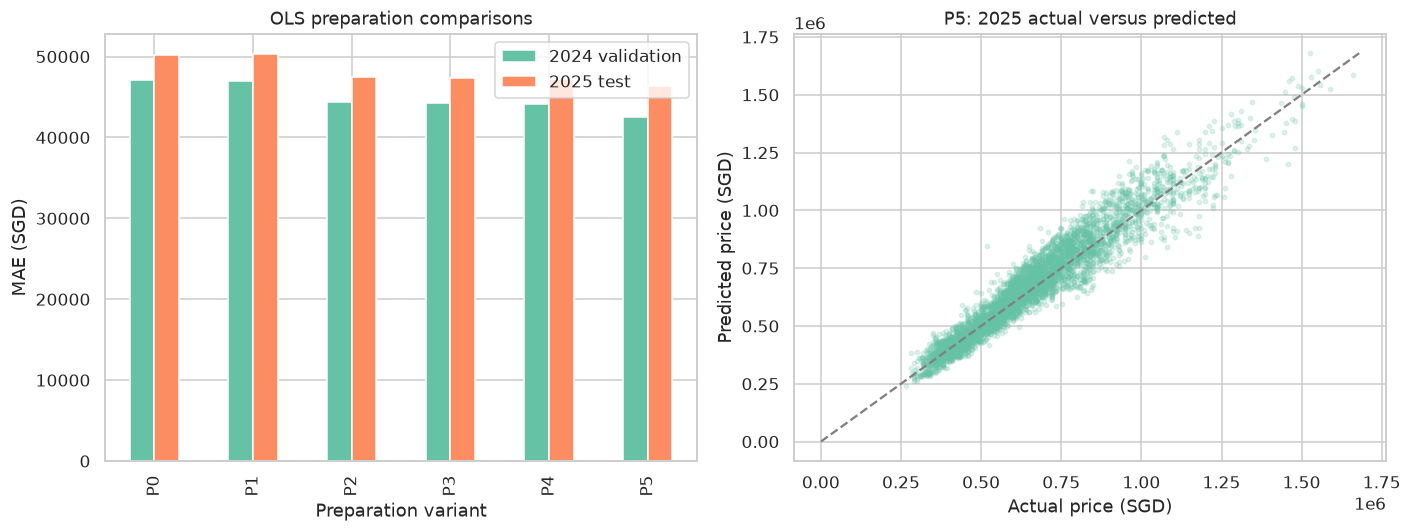

In [37]:
prediction_rows = []
test_predictions = pd.DataFrame(index=test.index)
prediction_models = {}
for name, formula in prediction_formulas.items():
    validation_fit, validation_info = fit_hedonic(formula, development, clustered=False)
    validation_log = predict_log(validation_fit, validation_info, validation)
    validation_scores = prediction_scores(validation["resale_price"], validation_log, np.exp(validation_fit.resid).mean())

    fit, info = fit_hedonic(formula, training, clustered=False)
    predicted_log = predict_log(fit, info, test)
    smearing = np.exp(fit.resid).mean()
    scores = prediction_scores(test["resale_price"], predicted_log, smearing)
    test_predictions[name] = np.exp(predicted_log) * smearing
    prediction_models[name] = (fit, info, smearing)
    prediction_rows.append({"variant": name, "training_rows": len(training), "test_rows": len(test),
                            "validation_MAE_SGD": validation_scores["MAE_SGD"], **scores})

prediction_results = pd.DataFrame(prediction_rows).set_index("variant")
display(prediction_results)
assert prediction_results["test_rows"].eq(len(test)).all()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
prediction_results[["validation_MAE_SGD", "MAE_SGD"]].rename(
    columns={"validation_MAE_SGD": "2024 validation", "MAE_SGD": "2025 test"}
).plot.bar(ax=axes[0])
axes[0].set(title="OLS preparation comparisons", xlabel="Preparation variant", ylabel="MAE (SGD)")
comparison_sample = test.sample(5000, random_state=42)
axes[1].scatter(comparison_sample["resale_price"], test_predictions.loc[comparison_sample.index, "P5"], s=8, alpha=.2)
price_limit = max(comparison_sample["resale_price"].max(), test_predictions.loc[comparison_sample.index, "P5"].max())
axes[1].plot([0, price_limit], [0, price_limit], color="gray", linestyle="--")
axes[1].set(title="P5: 2025 actual versus predicted", xlabel="Actual price (SGD)", ylabel="Predicted price (SGD)")
plt.tight_layout()
plt.show()

### 18.1 Group errors and training-only cleaning sensitivity

Compare P0 and P5 errors by town and flat type. Group differences describe reliability across the available housing groups; they are not proof of demographic fairness because no protected demographic attributes are observed.

Separately refit the same P4-O specification (P4 with ordinal storey) with duplicate removal, lease flags restored, or prices restricted by a training-only IQR fence. Evaluate every version on the unchanged 2025 test set, including its valid expensive transactions. Ordinal storey is used consistently in this sensitivity comparison because price trimming eliminates the highest training storey category; a categorical coefficient for that absent group cannot be estimated. Historical target encoding is omitted from this cleaning comparison so that changing the training sample does not silently reuse encoder statistics from another cleaning policy.

In [38]:
group_error_rows = []
for grouping in ["town", "flat_type"]:
    for group, part in test.groupby(grouping):
        for name in ["P0", "P5"]:
            error = test_predictions.loc[part.index, name] - part["resale_price"]
            group_error_rows.append({"grouping": grouping, "group": group, "variant": name,
                                     "rows": len(part), "MAE_SGD": error.abs().mean(),
                                     "mean_error_SGD": error.mean()})
group_prediction_errors = pd.DataFrame(group_error_rows)
display(group_prediction_errors.pivot(index=["grouping", "group", "rows"], columns="variant", values="MAE_SGD"))

price_q1, price_q3 = training["resale_price"].quantile([.25, .75])
price_lower = price_q1 - 1.5 * (price_q3 - price_q1)
price_upper = price_q3 + 1.5 * (price_q3 - price_q1)
training_with_flags = all_valid.loc[all_valid["transaction_year"].between(2018, 2024)]
cleaning_training_sets = {
    "main": training,
    "deduplicated": training.loc[~training.duplicated(subset=list(raw.columns))],
    "lease_flags_retained": training_with_flags,
    "training_price_IQR": training.loc[training["resale_price"].between(price_lower, price_upper)],
}
cleaning_formula = prediction_formulas["P4"].replace(STOREY, "storey_ordinal")
cleaning_rows = []
tail_rows = []
for name, training_data in cleaning_training_sets.items():
    fit, info = fit_hedonic(cleaning_formula, training_data, clustered=False)
    predicted_log = predict_log(fit, info, test)
    smearing = np.exp(fit.resid).mean()
    scores = prediction_scores(test["resale_price"], predicted_log, smearing)
    cleaning_rows.append({"variant": name, "training_rows": len(training_data), "test_rows": len(test), **scores})
    predicted_price = np.exp(predicted_log) * smearing
    for tail_name, mask in {"inside_training_IQR": test["resale_price"].le(price_upper),
                            "above_training_IQR": test["resale_price"].gt(price_upper)}.items():
        error = predicted_price.loc[mask] - test.loc[mask, "resale_price"]
        tail_rows.append({"variant": name, "test_group": tail_name, "rows": int(mask.sum()),
                          "MAE_SGD": error.abs().mean(), "mean_error_SGD": error.mean()})
cleaning_prediction_results = pd.DataFrame(cleaning_rows).set_index("variant")
tail_prediction_errors = pd.DataFrame(tail_rows)
display(cleaning_prediction_results)
display(tail_prediction_errors.pivot(index=["test_group", "rows"], columns="variant", values="MAE_SGD"))

variant                                 P0        P5
grouping  group            rows                     
flat_type 1 ROOM           5      5109.768 12135.864
          2 ROOM           830   26409.786 27587.485
          3 ROOM           6132  42428.541 36047.758
          4 ROOM           10816 49947.875 46142.328
          5 ROOM           5766  58465.508 55141.792
          EXECUTIVE        1469  65771.132 66307.411
          MULTI-GENERATION 4     92380.291 76797.858
town      ANG MO KIO       970   36271.035 33974.396
          BEDOK            1206  36092.693 42828.806
          BISHAN           375   54754.439 53701.953
          BUKIT BATOK      1298  44389.962 59198.408
          BUKIT MERAH      929   86424.005 74307.401
          BUKIT PANJANG    798   49996.071 40558.698
          BUKIT TIMAH      54    61826.699 69915.232
          CENTRAL AREA     172   95010.358 50469.485
          CHOA CHU KANG    1026  36660.064 35381.721
          CLEMENTI         549   60715.398 62642.144
          GEYLANG          639   54833.529 47175.299
          HOUGANG          1312  56531.565 43758.496
          JURONG EAST      481   45543.928 40228.354
          JURONG WEST      1588  41205.506 41418.444
          KALLANG/WHAMPOA  792   67618.395 58915.414
          MARINE PARADE    162   54020.632 49138.456
          PASIR RIS        633   45192.999 39653.726
          PUNGGOL          1536  39550.813 40160.985
          QUEENSTOWN       603   69176.251 62951.767
          SEMBAWANG        1179  38881.434 34285.391
          SENGKANG         1896  46916.145 40316.233
          SERANGOON        400   73918.480 55036.334
          TAMPINES         1919  52439.062 55987.929
          TOA PAYOH        1060  76204.281 58245.844
          WOODLANDS        1745  34496.949 31944.483
          YISHUN           1700  54640.987 45152.710

,training_rows,test_rows,log_RMSE,MAE_SGD,RMSE_SGD,mean_error_SGD
variant,,,,,,
main,176407,25022,0.093,47377.724,63749.577,296.287
deduplicated,176283,25022,0.093,47378.734,63749.385,297.601
lease_flags_retained,176473,25022,0.093,47375.912,63747.701,301.563
training_price_IQR,173332,25022,0.093,47265.977,63997.844,-1655.660


,variant,deduplicated,lease_flags_retained,main,training_price_IQR
test_group,rows,,,,
above_training_IQR,1904,94726.096,94738.063,94743.324,98759.505
inside_training_IQR,23118,43479.202,43475.162,43476.690,43024.967


## 19. Draft findings and assignment reflection

The following observations are computed from this run, rather than assumed in advance. Town-premium changes are relative to the same reference; lease coefficients are conditional associations; predictive comparisons use the same held-out records. In-sample fit, coefficient significance, and prediction accuracy answer different questions.

In [39]:
largest_change_town = regional_change.index[0]
change = regional_change.loc[largest_change_town]
profile = town_profiles.loc[largest_change_town]
reference_profile = town_profiles.loc["BEDOK"]
step_changes = regional_path.loc[largest_change_town, ["M0", "M1", "M2", "M3", "M4"]].diff().dropna()
largest_step = step_changes.abs().idxmax()
area_only_change = prediction_results.loc["P1", "MAE_SGD"] - prediction_results.loc["P0", "MAE_SGD"]
prepared_bias = prediction_results.loc["P5", "mean_error_SGD"]
executive_first = executive_results.iloc[0]
executive_last = executive_results.iloc[-1]
baseline_mae = prediction_results.loc["P0", "MAE_SGD"]
prepared_mae = prediction_results.loc["P5", "MAE_SGD"]
tail_main = tail_prediction_errors.query("variant == 'main' and test_group == 'above_training_IQR'").iloc[0]
tail_trimmed = tail_prediction_errors.query("variant == 'training_price_IQR' and test_group == 'above_training_IQR'").iloc[0]

display(Markdown(f"""
- **Town composition:** {largest_change_town} has the largest absolute M0-to-M4 premium change: {change['premium_pct_M0']:.1f}% to {change['premium_pct_M4']:.1f}% relative to BEDOK, a change of {change['change_pp']:.1f} percentage points. The largest stepwise change occurs at {largest_step}. Its median area is {profile["median_area"]:.0f} sqm versus {reference_profile["median_area"]:.0f} sqm in BEDOK; EXECUTIVE shares are {profile["executive_share_pct"]:.1f}% versus {reference_profile["executive_share_pct"]:.1f}%. These observed composition differences support further investigation, not a causal decomposition.
- **Lease pattern:** For EXECUTIVE flats, the fitted ten-year lease association changes from {executive_first['ten_year_difference_pct']:.1f}% in E0 to {executive_last['ten_year_difference_pct']:.1f}% in E3 (95% interval {executive_last['low_pct']:.1f}% to {executive_last['high_pct']:.1f}%). This is a candidate non-obvious composition finding; it does not establish a causal lease effect.
- **Preparation evidence:** P0 test MAE is SGD {baseline_mae:,.0f}; P5 is SGD {prepared_mae:,.0f}. The signed MAE change is {prepared_mae - baseline_mae:,.0f} SGD. Compare the intermediate steps and group errors rather than crediting the entire change to one transformation.
- **Uneven gains:** The area-only P0-to-P1 test MAE change is {area_only_change:,.0f} SGD. P5 mean prediction error is {prepared_bias:,.0f} SGD (positive means overprediction). A lower overall MAE does not imply that bias or every group error improved.
- **Tail policy:** On the same {int(tail_main['rows']):,} expensive test transactions, P4-O MAE is SGD {tail_main['MAE_SGD']:,.0f} with the main training sample and SGD {tail_trimmed['MAE_SGD']:,.0f} after training-price IQR restriction. Price trimming also removes all observations in the highest original storey category. This tests whether deleting valid price tails harms coverage of those homes.
"""))


- **Town composition:** PASIR RIS has the largest absolute M0-to-M4 premium change: 25.9% to -12.5% relative to BEDOK, a change of -38.4 percentage points. The largest stepwise change occurs at M2. Its median area is 122 sqm versus 88 sqm in BEDOK; EXECUTIVE shares are 25.6% versus 5.0%. These observed composition differences support further investigation, not a causal decomposition.
- **Lease pattern:** For EXECUTIVE flats, the fitted ten-year lease association changes from -16.8% in E0 to 5.6% in E3 (95% interval 4.0% to 7.3%). This is a candidate non-obvious composition finding; it does not establish a causal lease effect.
- **Preparation evidence:** P0 test MAE is SGD 50,214; P5 is SGD 46,309. The signed MAE change is -3,905 SGD. Compare the intermediate steps and group errors rather than crediting the entire change to one transformation.
- **Uneven gains:** The area-only P0-to-P1 test MAE change is 83 SGD. P5 mean prediction error is 14,611 SGD (positive means overprediction). A lower overall MAE does not imply that bias or every group error improved.
- **Tail policy:** On the same 1,904 expensive test transactions, P4-O MAE is SGD 94,743 with the main training sample and SGD 98,760 after training-price IQR restriction. Price trimming also removes all observations in the highest original storey category. This tests whether deleting valid price tails harms coverage of those homes.


### Interpretation limits and next review

The main specifications impose common area/storey associations and largely common lease curvature. District amenities and detailed condition remain unobserved. Clustered standard errors address within-building dependence, but dependence across buildings may remain. Confidence bands are pointwise; town rankings are not simultaneous hypothesis tests. A large sample can make small differences statistically significant.

The price level is nominal SGD. Explanatory month indicators absorb shared time changes without identifying inflation or a causal market index. The forecasting trend is a deliberately simple validation-selected extrapolation; 2025 performance may reflect market drift as well as preparation quality. Target-encoded priors can also lag that drift.

For the assignment, select one well-supported finding, investigate its possible causes using the intermediate results and group distributions, and explain the preparation decision it motivates. Retain both improvements and deterioration in prediction results. Review the regression assumptions, regional overlap, rare-group uncertainty, member contributions, and the AI declaration before preparing the maximum 12-minute presentation. All model results remain in notebook variables and outputs; no processed data files are exported.